# SARS-CoV-2 Spike Protein Variation Across Alpha, Delta and Omicron

**Computing Bioinformatics — Group Project**

This notebook compares amino-acid variation in the SARS-CoV-2 spike protein
between the Alpha, Delta and Omicron variants, asks how much of the
variant-distinguishing signal lies outside the receptor-binding domain, and
tests whether an isolate's geographic region can be predicted from its spike
sequence.

It runs top to bottom in Google Colab. Set `DOWNLOAD_FRESH = True` in Stage 2
to rebuild the dataset from NCBI instead of using the copy stored with the
project.

## Stage 0. Setup

The project code is written to files here so the notebook is self-contained:
it does not depend on a checkout being present. Each module is also kept in
`src/` in the repository.

In [1]:
import sys, subprocess
def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

# Colab already has most of these; this is a no-op when they are present.
pip_install("biopython", "scikit-learn", "statsmodels", "seaborn")

import warnings
warnings.filterwarnings("ignore")
print("Python", sys.version.split()[0])

Python 3.13.18


In [2]:
%%writefile spike_reference.py
"""Reference layer for the SARS-CoV-2 spike project.

Provides:
  * the Wuhan-Hu-1 (MN908947) spike protein sequence, translated from the genome
  * spike domain coordinates used for Stage 6 annotation
  * variant-defining spike mutations parsed from CoVariants

All coordinates are 1-based amino-acid positions in the mature S protein
numbering used throughout the SARS-CoV-2 literature (S starts at M1).
"""
from __future__ import annotations

import json
from pathlib import Path

from Bio.Seq import Seq

# Spike CDS in MN908947 / NC_045512.2, 1-based inclusive.
SPIKE_CDS_START = 21563
SPIKE_CDS_END = 25384
EXPECTED_SPIKE_LENGTH = 1273

# Domain boundaries, 1-based inclusive, in S protein numbering.
# Non-overlapping structural partition used for per-position annotation.
SPIKE_DOMAINS = {
    "Signal peptide": (1, 13),
    "NTD": (14, 305),
    "NTD-RBD linker": (306, 318),
    "RBD": (319, 541),
    "SD1": (542, 590),
    "SD2": (591, 680),
    "S1/S2 furin site": (681, 685),
    "S2 N-terminal": (686, 815),
    "Fusion peptide": (816, 833),
    "FP-HR1 linker": (834, 911),
    "HR1": (912, 984),
    "Central helix": (985, 1035),
    "CD-proximal": (1036, 1075),
    "Connector domain": (1076, 1141),
    "HR2-proximal": (1142, 1162),
    "HR2": (1163, 1213),
    "Transmembrane": (1214, 1237),
    "Cytoplasmic tail": (1238, 1273),
}

# Receptor-binding motif: the RBD sub-region that makes direct ACE2 contact.
RBM = (437, 508)
RBD = SPIKE_DOMAINS["RBD"]
FURIN_SITE = SPIKE_DOMAINS["S1/S2 furin site"]

# Nextstrain clade -> WHO variant label, for the groups this project analyses.
CLADE_TO_VARIANT = {
    "20I (Alpha, V1)": "Alpha",
    "21A (Delta)": "Delta",
    "21I (Delta)": "Delta",
    "21J (Delta)": "Delta",
    "21K (Omicron)": "Omicron",
    "21L (Omicron)": "Omicron",
    "22B (Omicron)": "Omicron",
}

# Pango lineage prefixes -> WHO variant label. Order matters: longest first.
PANGO_TO_VARIANT = [
    ("B.1.1.7", "Alpha"),
    ("Q.", "Alpha"),          # Q.* are Alpha sublineages
    ("B.1.617.2", "Delta"),
    ("AY.", "Delta"),         # AY.* are Delta sublineages
    ("B.1.1.529", "Omicron"),
    ("BA.", "Omicron"),
]


def load_reference_spike(genome_fasta: str | Path) -> str:
    """Translate the spike CDS out of the Wuhan-Hu-1 genome.

    Returns the 1273-residue protein with the terminal stop removed.
    """
    seq_lines = []
    with open(genome_fasta) as handle:
        for line in handle:
            if not line.startswith(">"):
                seq_lines.append(line.strip())
    genome = "".join(seq_lines).upper()

    cds = genome[SPIKE_CDS_START - 1 : SPIKE_CDS_END]
    protein = str(Seq(cds).translate())

    if not protein.endswith("*"):
        raise ValueError("Spike CDS did not end in a stop codon; check coordinates.")
    protein = protein[:-1]

    if "*" in protein:
        raise ValueError("Internal stop codon in translated spike; check coordinates.")
    if len(protein) != EXPECTED_SPIKE_LENGTH:
        raise ValueError(
            f"Spike length {len(protein)} != expected {EXPECTED_SPIKE_LENGTH}"
        )
    return protein


def annotate_position(pos: int) -> str:
    """Return the spike domain containing a 1-based residue position."""
    for name, (start, end) in SPIKE_DOMAINS.items():
        if start <= pos <= end:
            return name
    return "Outside annotated range"


def in_rbd(pos: int) -> bool:
    return RBD[0] <= pos <= RBD[1]


def in_rbm(pos: int) -> bool:
    return RBM[0] <= pos <= RBM[1]


def load_covariants_mutations(clusters_json: str | Path) -> dict[str, list[dict]]:
    """Parse CoVariants clusters.json into {clade: [spike mutations]}.

    Each mutation is {"ref": str, "pos": int, "alt": str}. 'alt' of "-" means
    a deletion. Only gene == "S" entries are kept.
    """
    with open(clusters_json) as handle:
        clusters = json.load(handle)["clusters"]

    out: dict[str, list[dict]] = {}
    for cluster in clusters:
        name = cluster.get("display_name")
        muts = (cluster.get("mutations") or {}).get("nonsynonymous") or []
        spike = [
            {"ref": m["left"], "pos": int(m["pos"]), "alt": m["right"]}
            for m in muts
            if m.get("gene") == "S" and m.get("pos") is not None
        ]
        if name:
            out[name] = sorted(spike, key=lambda m: m["pos"])
    return out


def defining_mutations_by_variant(
    clusters_json: str | Path,
) -> dict[str, dict[str, list[dict]]]:
    """Variant-defining spike mutations for the clades this project analyses."""
    all_clades = load_covariants_mutations(clusters_json)
    grouped: dict[str, dict[str, list[dict]]] = {}
    for clade, variant in CLADE_TO_VARIANT.items():
        if clade in all_clades:
            grouped.setdefault(variant, {})[clade] = all_clades[clade]
    return grouped


def variant_from_pango(lineage: str | None) -> str | None:
    """Map a Pango lineage string to Alpha / Delta / Omicron, else None."""
    if not lineage:
        return None
    text = str(lineage).strip()
    if not text or text.lower() in {"nan", "none", "unclassifiable"}:
        return None
    for prefix, variant in PANGO_TO_VARIANT:
        if text == prefix.rstrip(".") or text.startswith(prefix):
            return variant
    return None

Overwriting spike_reference.py


In [3]:
%%writefile align.py
"""Project spike protein sequences onto Wuhan-Hu-1 reference coordinates.

Every analysed sequence is represented as a fixed-length string of
EXPECTED_SPIKE_LENGTH (1273) characters, one per reference residue:

    an amino-acid letter  the residue aligned to that reference position
    '-'                   deletion relative to the reference
    'X'                   ambiguous or unresolved residue

Insertions relative to the reference are recorded separately rather than
widening the coordinate system, so that position 501 always means S:501 in the
numbering used by the literature. Insertions are rare in spike and are counted
but not used as model features; this is stated as a limitation.
"""
from __future__ import annotations

from Bio import Align

AMBIGUOUS = set("XBZJUO*")


def make_aligner() -> Align.PairwiseAligner:
    """Global protein aligner with gap costs that favour few, long gaps.

    BLOSUM62 with an open/extend penalty chosen so that the known spike
    deletions (for example the 69-70 and 142-144 deletions) come out as single
    contiguous gaps rather than scattered single-residue gaps.
    """
    aligner = Align.PairwiseAligner(scoring="blastp")
    aligner.mode = "global"
    aligner.open_gap_score = -11
    aligner.extend_gap_score = -1
    # Do not penalise gaps at the sequence ends: many records are 5'/3' truncated.
    for new_name, old_name in (("end_insertion_score", "target_end_gap_score"),
                               ("end_deletion_score", "query_end_gap_score")):
        try:
            setattr(aligner, new_name, 0.0)
        except AttributeError:
            setattr(aligner, old_name, 0.0)
    return aligner


def project_to_reference(
    query: str,
    reference: str,
    aligner: Align.PairwiseAligner | None = None,
) -> tuple[str, int]:
    """Align `query` to `reference` and return it in reference coordinates.

    Returns (projected, n_inserted_residues) where `projected` has the same
    length as `reference`.
    """
    aligner = aligner or make_aligner()
    query = query.upper().replace("*", "")

    alignment = aligner.align(reference, query)[0]
    ref_idx, qry_idx = alignment.aligned

    projected = ["-"] * len(reference)
    matched_ref = 0
    for (r_start, r_end), (q_start, q_end) in zip(ref_idx, qry_idx):
        block = query[q_start:q_end]
        for offset, residue in enumerate(block):
            projected[r_start + offset] = "X" if residue in AMBIGUOUS else residue
        matched_ref += r_end - r_start

    n_inserted = len(query) - matched_ref
    return "".join(projected), max(n_inserted, 0)


def mutations_vs_reference(
    projected: str,
    reference: str,
    skip_ambiguous: bool = True,
) -> list[tuple[str, int, str]]:
    """List (ref_aa, 1-based position, alt_aa) differences from the reference."""
    out = []
    for i, (ref_aa, alt_aa) in enumerate(zip(reference, projected), start=1):
        if alt_aa == ref_aa:
            continue
        if skip_ambiguous and alt_aa == "X":
            continue
        out.append((ref_aa, i, alt_aa))
    return out


def format_mutation(ref_aa: str, pos: int, alt_aa: str) -> str:
    """Render a mutation in the conventional notation, e.g. N501Y or H69del."""
    return f"{ref_aa}{pos}del" if alt_aa == "-" else f"{ref_aa}{pos}{alt_aa}"


# Regions where protein-level alignment cannot reliably place deletions.
# A contiguous deletion run next to a substituted residue admits several
# placements with different BLOSUM scores, so the highest-scoring alignment is
# not necessarily the one curated annotation reports. In BA.1, residues 142-144
# are deleted and 145 is substituted (Y145D); BLOSUM62 scores D against G142
# better than against Y145, so the aligner prefers the non-curated placement.
# Nucleotide-level codon-aware alignment (as used by Nextclade) avoids this.
# Per-position deletion calls in these windows are therefore treated as
# uncertain, and deletions are also summarised per region.
INDEL_AMBIGUOUS_REGIONS = [(69, 70), (141, 146), (156, 158), (211, 212), (241, 243)]


def is_indel_ambiguous(pos: int) -> bool:
    """True if a deletion call at this position is alignment-ambiguous."""
    return any(start <= pos <= end for start, end in INDEL_AMBIGUOUS_REGIONS)


def normalise_gaps(projected: str, reference: str) -> str:
    """Left-shift gap runs through score-equivalent placements.

    A gap run moves one position left when the residue displaced from its left
    edge lands on an identical reference residue, which leaves the alignment
    score unchanged. Applying this consistently makes deletion placement
    deterministic across sequences wherever several alignments tie.
    """
    chars = list(projected)
    n = len(chars)
    i = 0
    while i < n:
        if chars[i] != "-":
            i += 1
            continue
        j = i
        while j + 1 < n and chars[j + 1] == "-":
            j += 1
        start, end = i, j
        while (start > 0 and chars[start - 1] != "-"
               and reference[start - 1] == reference[end]):
            chars[end] = chars[start - 1]
            chars[start - 1] = "-"
            start -= 1
            end -= 1
        i = j + 1
    return "".join(chars)


def deletion_runs(projected: str) -> list[tuple[int, int]]:
    """Maximal runs of deleted positions as (start, end), 1-based inclusive."""
    runs, start = [], None
    for idx, ch in enumerate(projected, start=1):
        if ch == "-" and start is None:
            start = idx
        elif ch != "-" and start is not None:
            runs.append((start, idx - 1))
            start = None
    if start is not None:
        runs.append((start, len(projected)))
    return runs

Overwriting align.py


In [4]:
%%writefile qc.py
"""Stage 3: load, project, quality-filter and deduplicate the spike dataset.

Decisions taken here, and why.

Length. Records are kept when the deposited spike protein is long enough to
be a near-complete spike. Short records are truncated genes, not short
proteins, and their absent positions would otherwise be scored as deletions.

Ambiguity. Positions NCBI could not resolve arrive as X. A record with many X
positions carries little information and inflates apparent novelty, so
records above a small ambiguity fraction are dropped, and the X positions
that remain are excluded from mutation calls rather than counted as changes.

Deduplication. Identical sequences are common: many isolates of one variant
differ nowhere in spike. Leaving them in would place copies of the same
sequence in both the training and test folds, so a classifier could memorise
rather than generalise. One representative of each distinct sequence is kept.

Duplicates spanning regions are reported separately, because they bound what
the geographic task can achieve: where one sequence occurs in several
regions, no model reading only the sequence can assign all of them correctly.
That bound is measured rather than assumed.
"""
from __future__ import annotations

import collections
from dataclasses import dataclass, field
from pathlib import Path

import pandas as pd

import align
import spike_reference as ref

MIN_RAW_LENGTH = 1200
MAX_AMBIGUOUS_FRACTION = 0.02


def read_fasta(path: str | Path) -> dict[str, str]:
    seqs: dict[str, str] = {}
    header, chunks = None, []
    with open(path) as handle:
        for line in handle:
            if line.startswith(">"):
                if header:
                    seqs[header] = "".join(chunks)
                header, chunks = line[1:].strip().split("|")[0], []
            else:
                chunks.append(line.strip())
    if header:
        seqs[header] = "".join(chunks)
    return seqs


def parse_collection_date(value: str) -> pd.Timestamp | None:
    """Collection dates appear as YYYY, YYYY-MM or YYYY-MM-DD."""
    if not value or not isinstance(value, str):
        return None
    text = value.strip()
    for fmt in ("%Y-%m-%d", "%Y-%m", "%Y"):
        try:
            return pd.to_datetime(text, format=fmt)
        except (ValueError, TypeError):
            continue
    return None


@dataclass
class QCReport:
    """Record counts at each filtering step, for the Stage 3 before/after table."""
    steps: list[tuple[str, int]] = field(default_factory=list)
    notes: list[str] = field(default_factory=list)
    pre_dedup: "pd.DataFrame | None" = None

    def add(self, label: str, n: int) -> None:
        self.steps.append((label, n))

    def note(self, text: str) -> None:
        self.notes.append(text)

    def to_frame(self) -> pd.DataFrame:
        rows = []
        prev = None
        for label, n in self.steps:
            rows.append({"step": label, "records": n,
                         "removed": "" if prev is None else prev - n})
            prev = n
        return pd.DataFrame(rows)


def build_dataset(
    metadata_csv: str | Path,
    fasta_path: str | Path,
    reference: str,
    min_raw_length: int = MIN_RAW_LENGTH,
    max_ambiguous_fraction: float = MAX_AMBIGUOUS_FRACTION,
    verbose: bool = True,
) -> tuple[pd.DataFrame, QCReport]:
    """Return the analysis-ready table plus a record of what was filtered."""
    report = QCReport()
    meta = pd.read_csv(metadata_csv)
    seqs = read_fasta(fasta_path)

    report.add("Downloaded metadata records", len(meta))
    meta = meta.drop_duplicates(subset="accession", keep="first")
    report.add("Unique accessions", len(meta))

    meta["raw_spike"] = meta["accession"].map(seqs)
    meta = meta[meta["raw_spike"].notna()].copy()
    report.add("With a spike sequence", len(meta))

    meta["raw_length"] = meta["raw_spike"].str.len()
    meta = meta[meta["raw_length"] >= min_raw_length].copy()
    report.add(f"Spike length >= {min_raw_length} aa", len(meta))

    meta["collection_date"] = meta["collection_date"].map(parse_collection_date)
    meta = meta[meta["collection_date"].notna()].copy()
    report.add("With a parsable collection date", len(meta))

    # Project every sequence onto reference coordinates.
    aligner = align.make_aligner()
    projected, inserted = [], []
    for n, seq in enumerate(meta["raw_spike"], start=1):
        p, ins = align.project_to_reference(seq, reference, aligner)
        projected.append(align.normalise_gaps(p, reference))
        inserted.append(ins)
        if verbose and n % 250 == 0:
            print(f"    projected {n}/{len(meta)}", flush=True)
    meta["spike"] = projected
    meta["n_inserted"] = inserted

    meta["n_ambiguous"] = meta["spike"].str.count("X")
    meta["ambiguous_fraction"] = meta["n_ambiguous"] / len(reference)
    meta = meta[meta["ambiguous_fraction"] <= max_ambiguous_fraction].copy()
    report.add(f"Ambiguity <= {max_ambiguous_fraction:.0%} of positions", len(meta))

    # Deduplicate on the mutation profile, not the raw projected string.
    # Unresolved positions are excluded from mutation calls, so two records
    # differing only in where their X positions fall have the same biology but
    # different strings. Keying on the projected string would count them as
    # distinct and manufacture diversity that rises as the ambiguity threshold
    # is loosened. The mutation profile is invariant to that.
    meta["mutation_profile"] = [
        ";".join(align.format_mutation(*m)
                 for m in align.mutations_vs_reference(s, reference))
        for s in meta["spike"]
    ]

    # Quantify duplicates before removing them.
    groups = meta.groupby("mutation_profile")
    dup_groups = [g for _, g in groups if len(g) > 1]
    n_dup_records = sum(len(g) for g in dup_groups)
    cross_region = [g for g in dup_groups if g["region"].nunique() > 1]
    cross_variant = [g for g in dup_groups if g["variant"].nunique() > 1]
    report.note(
        f"{len(dup_groups)} distinct sequences occur more than once, covering "
        f"{n_dup_records} records.")
    report.note(
        f"{len(cross_region)} of those duplicate groups span more than one region. "
        f"Where one spike sequence occurs in several regions, no model reading only "
        f"the sequence can place all of them correctly, so this sets a ceiling on "
        f"geographic accuracy.")
    report.note(
        f"{len(cross_variant)} duplicate groups span more than one variant label.")

    report.pre_dedup = meta.copy()
    meta = meta.drop_duplicates(subset="mutation_profile", keep="first").copy()
    report.add("Unique spike mutation profiles", len(meta))

    meta["n_mutations"] = [
        len(align.mutations_vs_reference(s, reference)) for s in meta["spike"]
    ]
    meta["n_rbd_mutations"] = [
        sum(1 for _, pos, _ in align.mutations_vs_reference(s, reference)
            if ref.in_rbd(pos))
        for s in meta["spike"]
    ]
    meta["year_month"] = meta["collection_date"].dt.to_period("M").astype(str)
    return meta.reset_index(drop=True), report


def duplicate_region_ceiling(meta_before_dedup: pd.DataFrame) -> float:
    """Best accuracy any sequence-only region classifier could reach.

    For each distinct sequence, the best possible choice is its most common
    region; every other record sharing that sequence is necessarily wrong.
    """
    total = len(meta_before_dedup)
    if not total:
        return float("nan")
    best = sum(
        collections.Counter(g["region"]).most_common(1)[0][1]
        for _, g in meta_before_dedup.groupby("mutation_profile")
    )
    return best / total

Overwriting qc.py


In [5]:
%%writefile analysis.py
"""Stage 5: statistical comparison of spike variation between variants.

Two questions are tested.

Per position. For each of the 1273 reference positions, does the proportion of
isolates carrying a non-reference residue differ between Alpha, Delta and
Omicron? Each position gives a 3 x 2 contingency table, tested with a
chi-square test of independence, or Fisher's exact test where expected counts
are too small for the chi-square approximation to hold. Testing 1273 positions
inflates false positives, so p-values are corrected with Benjamini-Hochberg and
reported as q-values.

Mutation burden. Does the number of RBD mutations per isolate differ between
variants? Counts are small integers and far from normal, so the omnibus test is
Kruskal-Wallis, followed by pairwise Mann-Whitney U tests with
Benjamini-Hochberg correction across the three comparisons.

Statistical significance is separated from effect size throughout. With
hundreds of sequences a difference of a few percent reaches significance while
meaning little biologically, so the frequency difference is reported alongside
every q-value.
"""
from __future__ import annotations

import itertools

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

import align
import spike_reference as ref

AMBIGUOUS_CHAR = "X"


def mutation_matrix(df: pd.DataFrame, reference: str,
                    column: str = "spike") -> pd.DataFrame:
    """Boolean matrix of isolates x positions, True where the residue differs.

    Unresolved (X) positions are recorded as missing rather than as mutations,
    so they are excluded from each position's test instead of being counted as
    changes.
    """
    n, length = len(df), len(reference)
    data = np.zeros((n, length), dtype=object)
    for i, seq in enumerate(df[column].to_numpy()):
        row = np.fromiter((c != r for c, r in zip(seq, reference)),
                          dtype=bool, count=length)
        amb = np.fromiter((c == AMBIGUOUS_CHAR for c in seq),
                          dtype=bool, count=length)
        row_obj = row.astype(object)
        row_obj[amb] = None
        data[i] = row_obj
    return pd.DataFrame(data, index=df.index,
                        columns=pd.RangeIndex(1, length + 1, name="position"))


def per_position_tests(mut: pd.DataFrame, groups: pd.Series,
                       reference: str, min_count: int = 1) -> pd.DataFrame:
    """Test each position for a difference in mutation frequency between groups."""
    labels = sorted(groups.dropna().unique())
    rows = []
    for pos in mut.columns:
        col = mut[pos]
        observed, freqs = [], {}
        for label in labels:
            vals = col[groups == label].dropna()
            mutated = int(vals.sum())
            total = int(len(vals))
            observed.append([mutated, total - mutated])
            freqs[label] = mutated / total if total else np.nan
        table = np.array(observed, dtype=float)
        total_mutated = table[:, 0].sum()
        if total_mutated < min_count or table.sum() == 0:
            continue
        # Chi-square needs adequate expected counts; otherwise use Fisher.
        try:
            chi2, p, _, expected = stats.chi2_contingency(table)
            test = "chi-square"
            if (expected < 5).any():
                raise ValueError
        except Exception:
            try:
                if table.shape[0] == 2:
                    _, p = stats.fisher_exact(table)
                else:
                    p = stats.fisher_exact(table)[1] if table.shape == (2, 2) else \
                        stats.chi2_contingency(table + 0.5)[1]
                test = "Fisher / corrected chi-square"
            except Exception:
                continue
        values = [v for v in freqs.values() if not np.isnan(v)]
        rows.append({
            "position": int(pos),
            "ref_aa": reference[int(pos) - 1],
            "domain": ref.annotate_position(int(pos)),
            "in_rbd": ref.in_rbd(int(pos)),
            "in_rbm": ref.in_rbm(int(pos)),
            **{f"freq_{label}": freqs[label] for label in labels},
            "max_freq_difference": (max(values) - min(values)) if values else np.nan,
            "n_mutated_total": int(total_mutated),
            "test": test,
            "p_value": p,
        })
    out = pd.DataFrame(rows)
    if out.empty:
        return out
    out["q_value"] = multipletests(out["p_value"], method="fdr_bh")[1]
    return out.sort_values("q_value").reset_index(drop=True)


def burden_comparison(df: pd.DataFrame, value: str = "n_rbd_mutations",
                      group: str = "variant") -> dict:
    """Kruskal-Wallis omnibus plus BH-corrected pairwise Mann-Whitney tests."""
    labels = sorted(df[group].dropna().unique())
    samples = [df.loc[df[group] == g, value].to_numpy() for g in labels]
    H, p_omnibus = stats.kruskal(*samples)

    pairs, raw_p, effects = [], [], []
    for a, b in itertools.combinations(labels, 2):
        x = df.loc[df[group] == a, value].to_numpy()
        y = df.loc[df[group] == b, value].to_numpy()
        U, p = stats.mannwhitneyu(x, y, alternative="two-sided")
        # Rank-biserial correlation: the effect size matching Mann-Whitney.
        rbc = 2 * U / (len(x) * len(y)) - 1
        pairs.append(f"{a} vs {b}")
        raw_p.append(p)
        effects.append({"median_a": float(np.median(x)), "median_b": float(np.median(y)),
                        "rank_biserial": float(rbc), "n_a": len(x), "n_b": len(y)})
    q = multipletests(raw_p, method="fdr_bh")[1] if raw_p else []
    pairwise = pd.DataFrame([
        {"comparison": c, "p_value": p, "q_value": qq, **e}
        for c, p, qq, e in zip(pairs, raw_p, q, effects)
    ])
    return {
        "groups": labels,
        "medians": {g: float(np.median(s)) for g, s in zip(labels, samples)},
        "kruskal_H": float(H),
        "kruskal_p": float(p_omnibus),
        "pairwise": pairwise,
    }


def domain_summary(results: pd.DataFrame, alpha: float = 0.05) -> pd.DataFrame:
    """Significant positions per spike domain, normalised by domain length."""
    sig = results[results["q_value"] < alpha]
    rows = []
    for domain, (start, end) in ref.SPIKE_DOMAINS.items():
        length = end - start + 1
        tested = int((results["domain"] == domain).sum())
        n_sig = int((sig["domain"] == domain).sum())
        rows.append({
            "domain": domain, "start": start, "end": end, "length_aa": length,
            "positions_tested": tested, "significant": n_sig,
            "significant_per_100aa": round(100 * n_sig / length, 2),
        })
    return pd.DataFrame(rows).sort_values("significant_per_100aa", ascending=False)


def top_mutations_by_variant(df: pd.DataFrame, reference: str,
                             variant: str, n: int = 15) -> pd.DataFrame:
    """Most frequent mutations within one variant, with domain annotation."""
    sub = df[df["variant"] == variant]
    counts: dict[tuple, int] = {}
    for seq in sub["spike"]:
        for m in align.mutations_vs_reference(seq, reference):
            counts[m] = counts.get(m, 0) + 1
    rows = [{
        "mutation": align.format_mutation(*m),
        "position": m[1],
        "domain": ref.annotate_position(m[1]),
        "in_rbd": ref.in_rbd(m[1]),
        "count": c,
        "frequency": c / len(sub) if len(sub) else np.nan,
        "indel_ambiguous": align.is_indel_ambiguous(m[1]),
    } for m, c in counts.items()]
    return (pd.DataFrame(rows).sort_values("count", ascending=False)
            .head(n).reset_index(drop=True))

Overwriting analysis.py


In [6]:
%%writefile ml.py
"""Stage 7: classification, ablation and clustering.

Three things are modelled, for different reasons.

Geographic origin, within one variant. This is the honest predictive task.
Region is not part of how a lineage is defined, so a model has to find real
signal, and it may fail. The variant is held fixed because region and variant
are confounded in GenBank: Omicron records are overwhelmingly North American,
so a model free to read the variant could infer the region from that instead
of from geography. Holding the variant fixed removes that shortcut.

Variant, as an ablation. Predicting variant from spike is circular, because
lineages are defined by these mutations, and both the model and a trivial
baseline score near 100%. It is still worth running as an ablation: comparing
the full spike against an RBD-masked spike and the RBD alone measures how much
variant signal sits outside the receptor-binding domain, which is a real
quantity rather than a restatement of the labels.

Clustering, unsupervised. Whether structure in spike sequence recovers the
variant labels without being told them, scored with the adjusted Rand index.

Leakage is controlled in three ways: identical mutation profiles are removed
before splitting, so no sequence appears in both training and test; feature
selection and scaling run inside each cross-validation fold through a
pipeline, never on the full dataset; and the test set is evaluated once.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_rand_score, balanced_accuracy_score,
                             classification_report, confusion_matrix,
                             roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline

import spike_reference as ref

RANDOM_STATE = 42


def mutation_features(df: pd.DataFrame, reference: str,
                      column: str = "spike") -> pd.DataFrame:
    """Binary isolates x positions matrix: 1 where the residue differs.

    Unresolved positions are encoded 0 (treated as "no evidence of a
    mutation") rather than 1, so missing data cannot masquerade as signal.
    """
    length = len(reference)
    rows = np.zeros((len(df), length), dtype=np.int8)
    for i, seq in enumerate(df[column].to_numpy()):
        for j, (c, r) in enumerate(zip(seq, reference)):
            if c != r and c != "X":
                rows[i, j] = 1
    return pd.DataFrame(rows, index=df.index,
                        columns=[f"pos_{p}" for p in range(1, length + 1)])


def mask_region(X: pd.DataFrame, start: int, end: int) -> pd.DataFrame:
    """Zero out a residue range, to remove its contribution to the model."""
    out = X.copy()
    cols = [f"pos_{p}" for p in range(start, end + 1) if f"pos_{p}" in out.columns]
    out[cols] = 0
    return out


def keep_only_region(X: pd.DataFrame, start: int, end: int) -> pd.DataFrame:
    """Keep only a residue range."""
    cols = [f"pos_{p}" for p in range(start, end + 1) if f"pos_{p}" in X.columns]
    return X[cols]


def build_models(k_features: int = 200) -> dict[str, Pipeline]:
    """Pipelines so that feature selection happens inside each fold."""
    return {
        "Majority-class baseline": Pipeline([
            ("clf", DummyClassifier(strategy="most_frequent")),
        ]),
        "Logistic regression": Pipeline([
            ("select", SelectKBest(chi2, k=k_features)),
            ("clf", LogisticRegression(max_iter=2000, class_weight="balanced",
                                       random_state=RANDOM_STATE)),
        ]),
        "Random forest": Pipeline([
            ("select", SelectKBest(chi2, k=k_features)),
            ("clf", RandomForestClassifier(n_estimators=400, class_weight="balanced",
                                           random_state=RANDOM_STATE, n_jobs=-1)),
        ]),
    }


def evaluate(X: pd.DataFrame, y: pd.Series, label: str,
             k_features: int = 200, test_size: float = 0.25,
             n_splits: int = 5, verbose: bool = True) -> pd.DataFrame:
    """Cross-validate on a training split, then score once on a held-out test set."""
    k_features = min(k_features, X.shape[1])
    counts = y.value_counts()
    if len(counts) < 2 or counts.min() < n_splits:
        if verbose:
            print(f"  [{label}] skipped: smallest class has {counts.min()} members, "
                  f"too few for {n_splits}-fold cross-validation")
        return pd.DataFrame()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=RANDOM_STATE)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

    rows = []
    for name, pipe in build_models(k_features).items():
        cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv,
                                    scoring="balanced_accuracy", n_jobs=1)
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        bacc = balanced_accuracy_score(y_test, pred)
        auc = np.nan
        if len(counts) == 2 and hasattr(pipe, "predict_proba"):
            try:
                proba = pipe.predict_proba(X_test)[:, 1]
                auc = roc_auc_score((y_test == pipe.classes_[1]).astype(int), proba)
            except Exception:
                pass
        rows.append({
            "task": label, "model": name,
            "cv_balanced_accuracy": round(float(np.mean(cv_scores)), 3),
            "cv_sd": round(float(np.std(cv_scores)), 3),
            "test_balanced_accuracy": round(float(bacc), 3),
            "test_roc_auc": round(float(auc), 3) if auc == auc else np.nan,
            "n_train": len(y_train), "n_test": len(y_test),
            "n_features": X.shape[1],
        })
    out = pd.DataFrame(rows)
    if verbose:
        print(f"\n  [{label}]  n={len(y)}  classes={dict(counts)}")
        print(out[["model", "cv_balanced_accuracy", "cv_sd",
                   "test_balanced_accuracy", "test_roc_auc"]].to_string(index=False))
    return out


def detailed_report(X: pd.DataFrame, y: pd.Series, k_features: int = 200,
                    test_size: float = 0.25) -> tuple[str, pd.DataFrame]:
    """Per-class report and confusion matrix for the stronger model."""
    k_features = min(k_features, X.shape[1])
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=RANDOM_STATE)
    pipe = build_models(k_features)["Random forest"]
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    labels = sorted(y.unique())
    cm = pd.DataFrame(confusion_matrix(y_test, pred, labels=labels),
                      index=[f"true {l}" for l in labels],
                      columns=[f"pred {l}" for l in labels])
    return classification_report(y_test, pred, zero_division=0), cm


def rbd_ablation(X: pd.DataFrame, y: pd.Series, k_features: int = 200) -> pd.DataFrame:
    """How much variant signal survives outside the receptor-binding domain."""
    start, end = ref.RBD
    variants = {
        "Full spike": X,
        "RBD masked": mask_region(X, start, end),
        "RBD only": keep_only_region(X, start, end),
        "NTD only": keep_only_region(X, *ref.SPIKE_DOMAINS["NTD"]),
    }
    frames = [evaluate(Xv, y, label, k_features=k_features, verbose=False)
              for label, Xv in variants.items()]
    return pd.concat([f for f in frames if not f.empty], ignore_index=True)


def clustering_report(X: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """Do unsupervised clusters recover the variant labels?"""
    k = y.nunique()
    rows = []
    for name, model in [
        ("KMeans", KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)),
        ("Agglomerative (Ward)", AgglomerativeClustering(n_clusters=k)),
    ]:
        labels = model.fit_predict(X.to_numpy(dtype=float))
        rows.append({"method": name, "n_clusters": k,
                     "adjusted_rand_index": round(adjusted_rand_score(y, labels), 3)})
    return pd.DataFrame(rows)


def redundancy_curve(X: pd.DataFrame, y: pd.Series, sizes=(1, 2, 3, 5, 10, 20, 50, 100),
                     n_repeats: int = 20, random_state: int = RANDOM_STATE) -> pd.DataFrame:
    """How many spike positions are needed to separate the variants?

    Masking the RBD does not reduce variant accuracy at all, which says the
    signal is not localised: it is repeated across the protein. To measure that
    redundancy, randomly chosen subsets of positions of increasing size are used
    as the only features. The size at which accuracy saturates is the number of
    arbitrary positions sufficient to identify a variant.

    Positions are drawn from those that actually vary, since constant columns
    carry no information and would only dilute the sample.
    """
    rng = np.random.default_rng(random_state)
    varying = [c for c in X.columns if X[c].nunique() > 1]
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    rows = []
    for k in sizes:
        if k > len(varying):
            continue
        scores = []
        for _ in range(n_repeats):
            cols = list(rng.choice(varying, size=k, replace=False))
            pipe = Pipeline([("clf", RandomForestClassifier(
                n_estimators=200, class_weight="balanced",
                random_state=random_state, n_jobs=-1))])
            scores.append(cross_val_score(pipe, X[cols], y, cv=cv,
                                          scoring="balanced_accuracy").mean())
        rows.append({
            "n_positions": k,
            "mean_balanced_accuracy": round(float(np.mean(scores)), 3),
            "sd": round(float(np.std(scores)), 3),
            "min": round(float(np.min(scores)), 3),
            "max": round(float(np.max(scores)), 3),
        })
    return pd.DataFrame(rows)


def top_discriminative_positions(X: pd.DataFrame, y: pd.Series,
                                 reference: str, n: int = 15) -> pd.DataFrame:
    """Positions a random forest relies on most, with domain annotation."""
    model = RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                   random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(X, y)
    imp = pd.Series(model.feature_importances_, index=X.columns)
    top = imp.sort_values(ascending=False).head(n)
    rows = []
    for col, importance in top.items():
        pos = int(col.split("_")[1])
        group_freq = {g: float(X.loc[y == g, col].mean()) for g in sorted(y.unique())}
        rows.append({
            "position": pos,
            "ref_aa": reference[pos - 1],
            "domain": ref.annotate_position(pos),
            "in_rbd": ref.in_rbd(pos),
            "importance": round(float(importance), 4),
            **{f"freq_{g}": round(v, 3) for g, v in group_freq.items()},
        })
    return pd.DataFrame(rows)

Overwriting ml.py


In [7]:
import collections, json, textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, ".")
import spike_reference as sref
import align, qc, analysis, ml

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Alpha": "#4C72B0", "Delta": "#DD8452", "Omicron": "#55A868"}
Path("figures").mkdir(exist_ok=True)
print("modules loaded")

modules loaded


## Stage 1. Question and objectives

### Research question

How does amino-acid variation in the SARS-CoV-2 spike protein differ between
the Alpha, Delta and Omicron variants relative to the Wuhan-Hu-1 reference,
how much of the variant-distinguishing signal lies outside the
receptor-binding domain (RBD), and can an isolate's geographic region be
predicted from its spike sequence alone?

### Why the question is framed this way

An earlier version of this project asked only whether the variant could be
predicted from the spike sequence, and whether Omicron carries more RBD
mutations than Alpha and Delta. Both parts are answerable without collecting
any data, because Pango lineages are *defined* by their spike mutation
profiles. Counting the defining mutations in the CoVariants catalogue gives:

| Clade | Variant | Defining spike mutations | Of which in the RBD |
|---|---|---|---|
| 20I | Alpha | 10 | 1 |
| 21A / 21I / 21J | Delta | 10–11 | 2 |
| 21K (BA.1) | Omicron | 36 | 15 |
| 21L (BA.2) | Omicron | 31 | 16 |
| 22B (BA.5) | Omicron | 34 | 17 |

A classifier asked to predict variant from spike is therefore being asked to
rediscover its own labelling rule, and a hypothesis that Omicron has more RBD
mutations is arithmetic from the table above rather than an empirical finding.

The question was restructured around parts whose answers are *not* fixed in
advance, while keeping the variant comparison as descriptive work.

### Objectives

1. Retrieve spike protein sequences for Alpha, Delta and Omicron isolates from
   NCBI, with Pango lineage, collection date and geographic region, and filter
   them to a set of distinct, good-quality sequences.
2. Compare the frequency of non-reference residues at each of the 1273 spike
   positions between the three variants, using contingency tests with
   Benjamini-Hochberg correction, and compare RBD mutation burden per isolate
   using Kruskal-Wallis with pairwise follow-up tests.
3. Map the significant positions onto spike domains (NTD, RBD, receptor-binding
   motif, furin cleavage site, HR1, HR2) and compare them with the curated
   variant-defining mutations and the published literature.
4. Train classifiers to predict geographic region from spike sequence within a
   single variant, against a majority-class baseline, and measure how much
   variant signal survives when the RBD is removed.

### Hypotheses

**Mutation burden.** H0: the number of RBD mutations per isolate does not
differ between Alpha, Delta and Omicron. H1: it does differ. This is tested
for completeness, but the answer is effectively determined by the lineage
definitions, so it is reported as a check that the pipeline reproduces known
biology rather than as a discovery.

**Geographic prediction.** H0: spike sequence carries no information about the
geographic region an isolate came from, so a classifier performs no better
than a majority-class baseline. H1: it performs better. This hypothesis is
genuinely open, and a failure to reject H0 would be a valid result.

**Localisation of variant signal.** H0: removing the RBD does not reduce the
accuracy of variant classification, meaning the signal is not localised to the
RBD. This is tested by ablation.

## Stage 2. Data acquisition

### Sources

| Input | Source | Why |
|---|---|---|
| Wuhan-Hu-1 genome (GenBank MN908947) | Nextstrain `ncov`, `defaults/reference_seq.fasta` | Reference for all coordinates |
| Variant-defining mutations | CoVariants (`hodcroftlab/covariants`), `clusters.json` | Independent annotation for Stage 6 |
| Isolate metadata | NCBI Datasets v2 virus API, `dataset_report` | Pango lineage, collection date, geographic region |
| Spike protein sequences | NCBI E-utilities `efetch`, `rettype=fasta_cds_aa` | Annotated CDS translations |

Two notes on how the sequences were obtained, because the obvious routes do
not work. The NCBI Datasets download endpoint ignores
`include_annotation_type` in its per-accession form and returns only a
metadata report, while its taxon form offers no way to restrict to chosen
accessions and returns roughly 641 MB for a single lineage. E-utilities
`efetch` with `rettype=fasta_cds_aa` returns the annotated CDS translations
for specific accessions, from which the record labelled
`[protein=surface glycoprotein]` is the spike protein.

The reference spike is **translated from the genome** at CDS 21563..25384
rather than downloaded as a separate protein record, so the sequence and its
numbering cannot disagree.

In [8]:
REFERENCE_DIR = Path("data/reference")
RAW_DIR = Path("data/raw")
REFERENCE_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)

REFERENCE_FILES = {
    "wuhan_hu_1_genome.fasta":
        "https://raw.githubusercontent.com/nextstrain/ncov/master/defaults/reference_seq.fasta",
    "covariants_clusters.json":
        "https://raw.githubusercontent.com/hodcroftlab/covariants/master/web/public/data/clusters.json",
}

import urllib.request
for name, url in REFERENCE_FILES.items():
    target = REFERENCE_DIR / name
    if not target.exists():
        print(f"downloading {name}")
        urllib.request.urlretrieve(url, target)
    print(f"{name}: {target.stat().st_size:,} bytes")

wuhan_hu_1_genome.fasta: 30,412 bytes
covariants_clusters.json: 464,130 bytes


In [9]:
REFERENCE_SPIKE = sref.load_reference_spike(REFERENCE_DIR / "wuhan_hu_1_genome.fasta")
print(f"reference spike: {len(REFERENCE_SPIKE)} aa")
print(f"  N-terminus: {REFERENCE_SPIKE[:24]}")
print(f"  C-terminus: {REFERENCE_SPIKE[-24:]}")

# The numbering must match the literature, so check residues whose reference
# state is well known. If any of these is wrong, every position below is wrong.
KNOWN = {339: "G", 417: "K", 452: "L", 478: "T", 484: "E", 501: "N",
         570: "A", 614: "D", 681: "P", 716: "T", 982: "S", 1118: "D"}
bad = {p: (aa, REFERENCE_SPIKE[p - 1]) for p, aa in KNOWN.items()
       if REFERENCE_SPIKE[p - 1] != aa}
print(f"\nknown reference residues checked: {len(KNOWN)}, mismatches: {len(bad)}")
assert not bad, bad

reference spike: 1273 aa
  N-terminus: MFVFLVLLPLVSSQCVNLTTRTQL
  C-terminus: CGSCCKFDEDDSEPVLKGVKLHYT

known reference residues checked: 12, mismatches: 0


In [10]:
DEFINING = sref.defining_mutations_by_variant(REFERENCE_DIR / "covariants_clusters.json")
rows = []
for variant, clades in DEFINING.items():
    for clade, muts in clades.items():
        rows.append({
            "clade": clade, "variant": variant,
            "spike_mutations": len(muts),
            "rbd_mutations": sum(1 for m in muts if sref.in_rbd(m["pos"])),
            # Does our translated reference agree with CoVariants at every
            # position this clade annotates?
            "reference_mismatches": sum(
                1 for m in muts
                if len(m["ref"]) == 1 and m["pos"] <= len(REFERENCE_SPIKE)
                and REFERENCE_SPIKE[m["pos"] - 1] != m["ref"]),
        })
defining_table = pd.DataFrame(rows).sort_values(["variant", "clade"])
display(defining_table)
assert defining_table["reference_mismatches"].sum() == 0
print("Every reference residue annotated by CoVariants for these clades matches "
      "the translated reference.")

,clade,variant,spike_mutations,rbd_mutations,reference_mismatches
0,"20I (Alpha, V1)",Alpha,10,1,0
1,21A (Delta),Delta,10,2,0
2,21I (Delta),Delta,11,2,0
3,21J (Delta),Delta,10,2,0
4,21K (Omicron),Omicron,36,15,0
5,21L (Omicron),Omicron,31,16,0
6,22B (Omicron),Omicron,34,17,0


Every reference residue annotated by CoVariants for these clades matches the translated reference.


In [11]:
%%writefile build_dataset.py
"""Download the isolate-level dataset: spike proteins plus metadata.

Metadata comes from the NCBI Datasets v2 virus dataset report, which carries
the Pango lineage, the collection date and a continent-level geographic
region. Protein sequences come from E-utilities `efetch` with
`rettype=fasta_cds_aa`, which returns the annotated CDS translations; the
Datasets download endpoint was not usable here because its per-accession form
never serves sequence files and its taxon form only offers the whole lineage,
which is hundreds of megabytes.

Sampling is stratified by geographic region, because records come back
clustered by submitting laboratory and the first pages of any lineage are
dominated by a single country. Region counts stay uneven even so: that
reflects real differences in sequencing capacity and is reported rather than
corrected away.

Run: python3 -I src/build_dataset.py [target_per_variant]
"""
from __future__ import annotations

import collections
import csv
import json
import sys
import time
import urllib.parse
import urllib.request
from pathlib import Path

sys.path.insert(0, str(Path(__file__).parent))
import spike_reference as ref

UA = {"User-Agent": "strathmore-bioinformatics-coursework/1.0"}
DATASETS = "https://api.ncbi.nlm.nih.gov/datasets/v2alpha"
EUTILS = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils"

# Lineages sampled for each WHO variant label.
LINEAGES = {
    "Alpha":   ["B.1.1.7"],
    "Delta":   ["B.1.617.2", "AY.4"],
    "Omicron": ["BA.1", "BA.2", "BA.5"],
}

PAGE_SIZE = 1000
MAX_PAGES_PER_LINEAGE = 25
CAP_PER_REGION = 150
EFETCH_BATCH = 100
EFETCH_PAUSE = 0.5          # stay under the 3 requests/second anonymous limit
DATASETS_PAUSE = 0.25


def fetch(url: str, timeout: int = 300, retries: int = 4) -> bytes:
    last = None
    for attempt in range(retries):
        try:
            req = urllib.request.Request(url, headers=UA)
            with urllib.request.urlopen(req, timeout=timeout) as resp:
                return resp.read()
        except Exception as exc:
            last = exc
            time.sleep(2 ** attempt)
    raise RuntimeError(f"failed after {retries} attempts: {url}") from last


def collect_metadata(lineage: str, target: int) -> list[dict]:
    """Page the dataset report, keeping usable records balanced across regions.

    A record is usable when it is annotated and carries both a collection date
    and a geographic region. Genome-level `completeness` is deliberately not
    required: many full-length Alpha genomes are flagged PARTIAL because of
    terminal ambiguous bases while the spike CDS is complete and annotated.
    Sequence quality is judged later, on the spike protein itself.
    """
    kept: list[dict] = []
    per_region: collections.Counter = collections.Counter()
    token, scanned = None, 0

    for _ in range(MAX_PAGES_PER_LINEAGE):
        params = {"filter.pangolin_classification": lineage, "page_size": PAGE_SIZE}
        if token:
            params["page_token"] = token
        payload = json.loads(
            fetch(f"{DATASETS}/virus/taxon/sars2/dataset_report?"
                  + urllib.parse.urlencode(params))
        )
        reports = payload.get("reports") or []
        if not reports:
            break

        for rec in reports:
            scanned += 1
            iso = rec.get("isolate") or {}
            loc = rec.get("location") or {}
            region = loc.get("geographic_region")
            date = iso.get("collection_date")
            if not region or not date or rec.get("is_annotated") is False:
                continue
            if per_region[region] >= CAP_PER_REGION:
                continue
            kept.append({
                "accession": rec["accession"],
                "lineage": lineage,
                "variant": ref.variant_from_pango(lineage),
                "country": (loc.get("geographic_location") or "").split(":")[0].strip(),
                "region": region,
                "collection_date": date,
                "genome_length": rec.get("length"),
                "completeness": rec.get("completeness"),
            })
            per_region[region] += 1

        token = payload.get("next_page_token")
        if not token or len(kept) >= target:
            break
        time.sleep(DATASETS_PAUSE)

    print(f"  {lineage:12s} scanned {scanned:6d} -> kept {len(kept):5d}  "
          f"{dict(per_region)}", flush=True)
    return kept[:target]


def fetch_spikes(accessions: list[str]) -> dict[str, str]:
    """Return {accession: spike protein} using annotated CDS translations."""
    out: dict[str, str] = {}
    for i in range(0, len(accessions), EFETCH_BATCH):
        batch = accessions[i : i + EFETCH_BATCH]
        params = {"db": "nuccore", "id": ",".join(batch),
                  "rettype": "fasta_cds_aa", "retmode": "text"}
        text = fetch(f"{EUTILS}/efetch.fcgi?" + urllib.parse.urlencode(params),
                     timeout=600).decode("utf-8", "replace")
        cur, keep = None, False
        for line in text.splitlines():
            if line.startswith(">"):
                keep = "[protein=surface glycoprotein]" in line
                cur = line.split("|")[1].split("_prot")[0] if keep and "|" in line else None
                if cur:
                    out[cur] = []
            elif keep and cur:
                out[cur].append(line.strip())
        print(f"    efetch {i + len(batch):5d}/{len(accessions)}  "
              f"spikes so far {len(out)}", flush=True)
        time.sleep(EFETCH_PAUSE)
    return {k: "".join(v).replace("*", "").upper() for k, v in out.items()}


def main() -> None:
    target_per_variant = int(sys.argv[1]) if len(sys.argv) > 1 else 500
    out_dir = Path("data/raw")
    out_dir.mkdir(parents=True, exist_ok=True)

    print("Collecting metadata", flush=True)
    records: list[dict] = []
    for variant, lineages in LINEAGES.items():
        per_lineage = max(1, target_per_variant // len(lineages))
        for lineage in lineages:
            records.extend(collect_metadata(lineage, per_lineage))

    print(f"\n{len(records)} records with metadata", flush=True)
    print("Fetching spike proteins", flush=True)
    seqs = fetch_spikes([r["accession"] for r in records])

    rows = [r for r in records if r["accession"] in seqs]
    print(f"\n{len(rows)} records have a spike sequence "
          f"({len(records) - len(rows)} without)", flush=True)

    meta_path = out_dir / "metadata.csv"
    with open(meta_path, "w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)

    fasta_path = out_dir / "spike_proteins.fasta"
    with open(fasta_path, "w") as handle:
        for r in rows:
            handle.write(f">{r['accession']}|{r['lineage']}|{r['variant']}|"
                         f"{r['region']}|{r['collection_date']}\n")
            seq = seqs[r["accession"]]
            for i in range(0, len(seq), 60):
                handle.write(seq[i : i + 60] + "\n")

    counts = collections.Counter((r["variant"], r["region"]) for r in rows)
    print(f"\nwrote {meta_path} and {fasta_path}")
    print("\nvariant x region:")
    for (v, reg), n in sorted(counts.items()):
        print(f"  {v:8s} {reg:16s} {n}")


if __name__ == "__main__":
    main()

Overwriting build_dataset.py


In [12]:
%%writefile topup.py
"""Deepen the sample for chosen lineages and regions.

Within a variant, spike carries limited diversity: thousands of isolates
collapse to a few hundred distinct mutation profiles. The geographic task is
therefore limited by distinct profiles rather than by record count, and the
only way to gain power is to scan more records and keep the new profiles.

Run: python3 -I src/topup.py <cap_per_region> <max_pages> <lineage> [lineage ...]
"""
from __future__ import annotations

import collections
import csv
import json
import sys
import time
import urllib.parse
from pathlib import Path

sys.path.insert(0, str(Path(__file__).parent))
import build_dataset as bd
import spike_reference as ref

CAP = int(sys.argv[1])
PAGES = int(sys.argv[2])
LINEAGES = sys.argv[3:]
# Regions worth deepening: the ones with enough records to support a model.
WANTED = {"Europe", "North America", "Africa", "Asia", "South America"}

meta_path = Path("data/raw/metadata.csv")
fasta_path = Path("data/raw/spike_proteins.fasta")
existing = {r["accession"] for r in csv.DictReader(open(meta_path))}
print(f"{len(existing)} accessions already held", flush=True)

for lineage in LINEAGES:
    kept: list[dict] = []
    per_region: collections.Counter = collections.Counter()
    token, scanned = None, 0
    for page in range(PAGES):
        params = {"filter.pangolin_classification": lineage, "page_size": bd.PAGE_SIZE}
        if token:
            params["page_token"] = token
        try:
            payload = json.loads(bd.fetch(
                f"{bd.DATASETS}/virus/taxon/sars2/dataset_report?"
                + urllib.parse.urlencode(params)))
        except Exception as exc:
            print(f"  {lineage} page {page} failed: {exc}", flush=True)
            break
        reports = payload.get("reports") or []
        if not reports:
            break
        for rec in reports:
            scanned += 1
            iso, loc = rec.get("isolate") or {}, rec.get("location") or {}
            region, date = loc.get("geographic_region"), iso.get("collection_date")
            if (not region or not date or region not in WANTED
                    or rec.get("is_annotated") is False
                    or rec["accession"] in existing
                    or per_region[region] >= CAP):
                continue
            kept.append({
                "accession": rec["accession"], "lineage": lineage,
                "variant": ref.variant_from_pango(lineage),
                "country": (loc.get("geographic_location") or "").split(":")[0].strip(),
                "region": region, "collection_date": date,
                "genome_length": rec.get("length"),
                "completeness": rec.get("completeness"),
            })
            per_region[region] += 1
            existing.add(rec["accession"])
        token = payload.get("next_page_token")
        if page % 20 == 0:
            print(f"  {lineage} page {page:3d} scanned {scanned:6d} "
                  f"new {len(kept):5d} {dict(per_region)}", flush=True)
        if not token:
            break
        time.sleep(bd.DATASETS_PAUSE)

    print(f"{lineage}: scanned {scanned}, new {len(kept)} {dict(per_region)}", flush=True)
    if not kept:
        continue
    seqs = bd.fetch_spikes([r["accession"] for r in kept])
    rows = [r for r in kept if r["accession"] in seqs]
    print(f"{lineage}: {len(rows)} with spike", flush=True)
    if not rows:
        continue
    with open(meta_path, "a", newline="") as handle:
        csv.DictWriter(handle, fieldnames=list(rows[0].keys())).writerows(rows)
    with open(fasta_path, "a") as handle:
        for r in rows:
            handle.write(f">{r['accession']}|{r['lineage']}|{r['variant']}|"
                         f"{r['region']}|{r['collection_date']}\n")
            s = seqs[r["accession"]]
            for i in range(0, len(s), 60):
                handle.write(s[i:i + 60] + "\n")
    print(f"{lineage}: appended", flush=True)

Overwriting topup.py


### Building the isolate dataset

`DOWNLOAD_FRESH` controls where the data comes from. With the default `False`,
the notebook uses the dataset stored with the project, which is what produced
the results reported here. Set it to `True` to rebuild from NCBI; that takes
roughly an hour because the sample is deepened to find enough *distinct* spike
sequences, for the reason explained in Stage 3.

Sampling is stratified by geographic region. Records come back clustered by
submitting laboratory, so the first pages of any lineage are dominated by a
single country, and an unstratified sample would be almost entirely one region.

In [13]:
DOWNLOAD_FRESH = False
TARGET_PER_VARIANT = 500

metadata_path = RAW_DIR / "metadata.csv"
fasta_path = RAW_DIR / "spike_proteins.fasta"

if DOWNLOAD_FRESH or not (metadata_path.exists() and fasta_path.exists()):
    print("Building the dataset from NCBI. This takes a while.")
    subprocess.run([sys.executable, "-I", "build_dataset.py", str(TARGET_PER_VARIANT)],
                   check=True)
    # Deepen Alpha and Delta: the geographic task is limited by the number of
    # distinct spike sequences, not by the number of records.
    subprocess.run([sys.executable, "-I", "topup.py", "2500", "120",
                    "B.1.1.7", "B.1.617.2", "AY.4"], check=False)
else:
    print("Using the dataset stored with the project.")

print(f"metadata: {metadata_path.stat().st_size:,} bytes")
print(f"sequences: {fasta_path.stat().st_size:,} bytes")

Using the dataset stored with the project.
metadata: 999,593 bytes
sequences: 20,030,090 bytes


### What every variable means

| Column | Type | Meaning |
|---|---|---|
| `accession` | string | NCBI nucleotide accession, unique per isolate |
| `lineage` | string | Pango lineage as assigned by NCBI |
| `variant` | string | WHO label (Alpha, Delta, Omicron) derived from the lineage |
| `country` | string | Country of collection |
| `region` | string | Continent-level region, used as the geographic label |
| `collection_date` | date | When the sample was taken, not when it was deposited |
| `genome_length` | integer | Length of the deposited genome in bases |
| `completeness` | string | NCBI's `COMPLETE` / `PARTIAL` flag for the genome |
| `raw_spike` | string | Spike protein exactly as deposited, variable length |
| `spike` | string | Spike projected onto the 1273 reference positions |
| `n_inserted` | integer | Residues inserted relative to the reference |
| `n_ambiguous` | integer | Unresolved (X) positions after projection |
| `mutation_profile` | string | Semicolon-separated mutations, the deduplication key |
| `n_mutations` | integer | Non-reference residues, excluding X |
| `n_rbd_mutations` | integer | Of those, how many fall in the RBD (319–541) |

In [14]:
raw_metadata = pd.read_csv(metadata_path)
print(f"{len(raw_metadata):,} records downloaded")
display(raw_metadata.head(3))
print("\nRecords by variant and region, before any filtering:")
display(raw_metadata.groupby(["variant", "region"]).size().unstack(fill_value=0))

14,965 records downloaded


,accession,lineage,variant,country,region,collection_date,genome_length,completeness
0,QB065669.1,B.1.1.7,Alpha,Germany,Europe,2021-02-01,29758,PARTIAL
1,QB065668.1,B.1.1.7,Alpha,Germany,Europe,2021-02-01,29758,PARTIAL
2,QB065667.1,B.1.1.7,Alpha,Germany,Europe,2021-02-01,29758,PARTIAL



Records by variant and region, before any filtering:


region,Africa,Asia,Europe,North America,South America
variant,,,,,
Alpha,81,50,3250,3250,2
Delta,50,200,2700,666,0
Omicron,311,173,1256,2831,145


## Stage 3. Preprocessing and quality control

Four decisions are made here, each for a stated reason.

**Length.** Records whose deposited spike is shorter than 1200 residues are
dropped. These are truncated genes rather than short proteins, and their
absent positions would otherwise be scored as deletions.

**Genome completeness is deliberately *not* used as a filter.** Many
full-length Alpha genomes of about 29,758 bases are flagged `PARTIAL` because
of ambiguous bases at the ends, while the spike CDS is complete and annotated.
Requiring `COMPLETE` would silently remove most Alpha isolates and bias the
comparison. Quality is judged on the spike protein itself.

**Ambiguity.** Positions NCBI could not resolve arrive as `X`. Records with
more than 2% ambiguous positions are dropped, and the `X` positions that
remain are excluded from mutation calls rather than counted as changes.

**Deduplication, on the mutation profile rather than the sequence string.**
Many isolates of one variant differ nowhere in spike, and leaving duplicates
in would place copies of the same sequence in both the training and test folds.
The key matters: because `X` positions are excluded from mutation calls, two
records differing only in *where* their unresolved positions fall have
identical biology but different strings. Keying on the string counts them as
distinct and manufactures diversity that grows as the ambiguity threshold is
loosened. Keying on the mutation profile is invariant to that. On this dataset
the string key gave 512 "unique" sequences where the profile key gives 401, so
the artefact was real and material.

In [15]:
dataset, report = qc.build_dataset(metadata_path, fasta_path, REFERENCE_SPIKE,
                                   verbose=False)
print("Records remaining after each step:\n")
display(report.to_frame())
print("\nWhat the duplicates imply:")
for note in report.notes:
    print(textwrap.fill(f"- {note}", 95, subsequent_indent="  "))

Records remaining after each step:



,step,records,removed
0,Downloaded metadata records,14965,
1,Unique accessions,14965,0
2,With a spike sequence,14965,0
3,Spike length >= 1200 aa,14950,15
4,With a parsable collection date,14949,1
5,Ambiguity <= 2% of positions,8756,6193
6,Unique spike mutation profiles,1406,7350



What the duplicates imply:
- 445 distinct sequences occur more than once, covering 7795 records.
- 77 of those duplicate groups span more than one region. Where one spike sequence occurs in
  several regions, no model reading only the sequence can place all of them correctly, so this
  sets a ceiling on geographic accuracy.
- 0 duplicate groups span more than one variant label.


In [16]:
print(f"{len(dataset):,} distinct spike sequences enter the analysis\n")
display(dataset.groupby(["variant", "region"]).size().unstack(fill_value=0))

print("Variant totals:", dict(dataset["variant"].value_counts()))
print("Collection dates:", dataset["collection_date"].min().date(),
      "to", dataset["collection_date"].max().date())

1,406 distinct spike sequences enter the analysis



region,Africa,Asia,Europe,North America,South America
variant,,,,,
Alpha,15,5,171,358,0
Delta,11,34,273,117,0
Omicron,51,12,109,205,45


Variant totals: {'Alpha': np.int64(549), 'Delta': np.int64(435), 'Omicron': np.int64(422)}
Collection dates: 2020-12-25 to 2024-12-02


In [17]:
# The ceiling that duplicate sequences place on geographic prediction. Where one
# spike sequence occurs in several regions, no model reading only the sequence
# can place all of those records correctly. `report.pre_dedup` is the filtered
# table before duplicates were collapsed, so no re-projection is needed.
pre_dedup = report.pre_dedup
ceiling_all = qc.duplicate_region_ceiling(pre_dedup)

alpha_pre = pre_dedup[(pre_dedup["variant"] == "Alpha")
                      & (pre_dedup["region"].isin(["Europe", "North America"]))]
ceiling_alpha = qc.duplicate_region_ceiling(alpha_pre)

print(f"Records before deduplication: {len(pre_dedup):,}")
print(f"Best achievable region accuracy from sequence alone, all variants: {ceiling_all:.3f}")
print(f"Same, restricted to Alpha in Europe and North America:            {ceiling_alpha:.3f}")
print()
print("This is an upper bound, not a model score: identical sequences collected in")
print("different regions cannot all be assigned correctly by any model that sees")
print("only the sequence.")

Records before deduplication: 8,756
Best achievable region accuracy from sequence alone, all variants: 0.890
Same, restricted to Alpha in Europe and North America:            0.871

This is an upper bound, not a model score: identical sequences collected in
different regions cannot all be assigned correctly by any model that sees
only the sequence.


## Stage 4. Exploratory data analysis

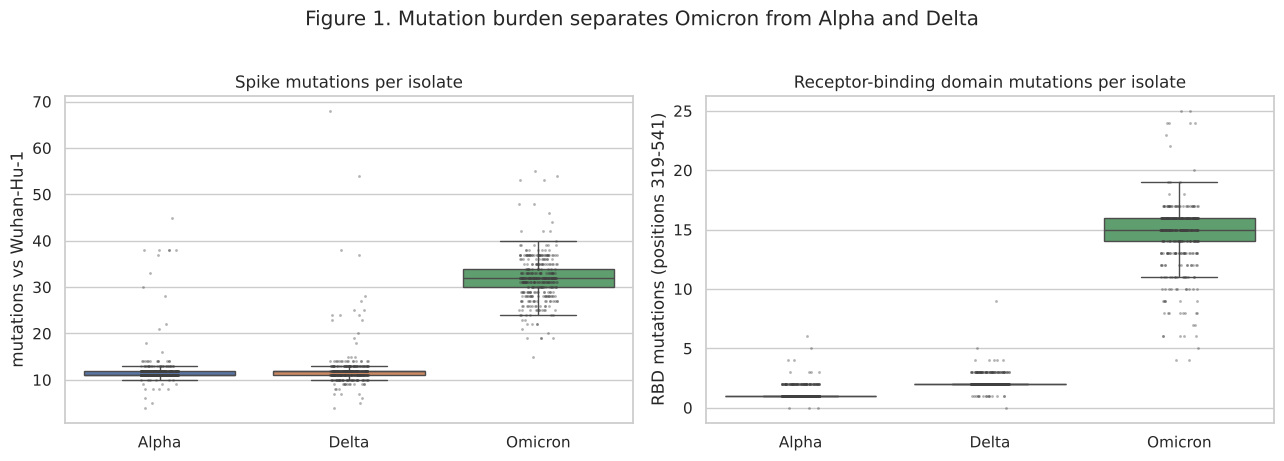

n_mutations                n_rbd_mutations               
             median   mean min max          median   mean min max
variant                                                          
Alpha          11.0  11.95   4  45             1.0   1.21   0   6
Delta          12.0  12.22   4  68             2.0   2.17   0   9
Omicron        32.0  31.86  15  55            15.0  14.60   4  25

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = ["Alpha", "Delta", "Omicron"]

sns.boxplot(data=dataset, x="variant", y="n_mutations", order=order,
            palette=PALETTE, ax=axes[0], showfliers=False)
sns.stripplot(data=dataset, x="variant", y="n_mutations", order=order,
              color="0.25", size=2, alpha=0.4, ax=axes[0])
axes[0].set(title="Spike mutations per isolate", xlabel="", ylabel="mutations vs Wuhan-Hu-1")

sns.boxplot(data=dataset, x="variant", y="n_rbd_mutations", order=order,
            palette=PALETTE, ax=axes[1], showfliers=False)
sns.stripplot(data=dataset, x="variant", y="n_rbd_mutations", order=order,
              color="0.25", size=2, alpha=0.4, ax=axes[1])
axes[1].set(title="Receptor-binding domain mutations per isolate", xlabel="",
            ylabel="RBD mutations (positions 319-541)")
fig.suptitle("Figure 1. Mutation burden separates Omicron from Alpha and Delta", y=1.02)
fig.tight_layout(); fig.savefig("figures/fig1_burden.png", dpi=150, bbox_inches="tight")
plt.show()

display(dataset.groupby("variant")[["n_mutations", "n_rbd_mutations"]]
        .agg(["median", "mean", "min", "max"]).round(2))

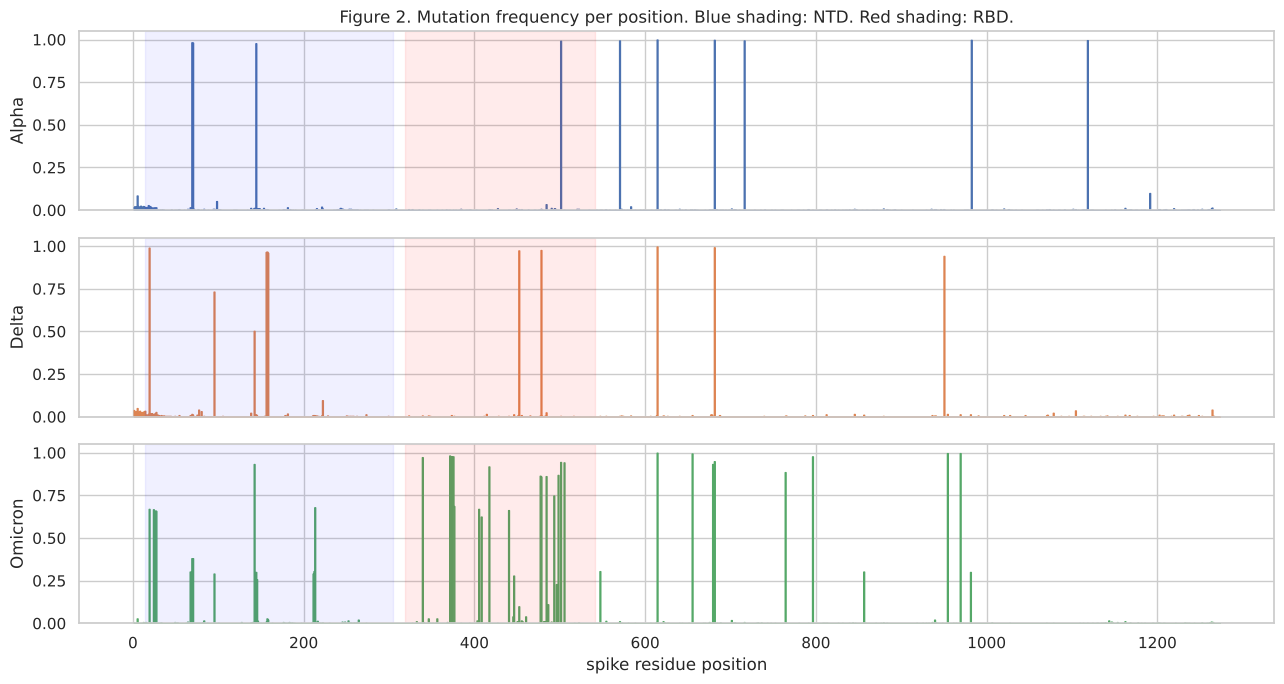

In [19]:
# Per-position mutation frequency along the protein, by variant.
freq_rows = []
for variant in order:
    sub = dataset[dataset["variant"] == variant]
    if sub.empty:
        continue
    arr = np.zeros(len(REFERENCE_SPIKE))
    for seq in sub["spike"]:
        for i, (c, r) in enumerate(zip(seq, REFERENCE_SPIKE)):
            if c != r and c != "X":
                arr[i] += 1
    freq_rows.append(pd.Series(arr / len(sub), name=variant))
freq_df = pd.concat(freq_rows, axis=1)
freq_df.index = np.arange(1, len(REFERENCE_SPIKE) + 1)

fig, axes = plt.subplots(len(freq_df.columns), 1, figsize=(13, 7), sharex=True)
for ax, variant in zip(np.atleast_1d(axes), freq_df.columns):
    ax.fill_between(freq_df.index, freq_df[variant], color=PALETTE[variant], step="mid")
    ax.set_ylim(0, 1.05); ax.set_ylabel(variant)
    ax.axvspan(*sref.RBD, color="red", alpha=0.08)
    ax.axvspan(*sref.SPIKE_DOMAINS["NTD"], color="blue", alpha=0.06)
np.atleast_1d(axes)[-1].set_xlabel("spike residue position")
np.atleast_1d(axes)[0].set_title(
    "Figure 2. Mutation frequency per position. Blue shading: NTD. Red shading: RBD.")
fig.tight_layout(); fig.savefig("figures/fig2_positions.png", dpi=150, bbox_inches="tight")
plt.show()

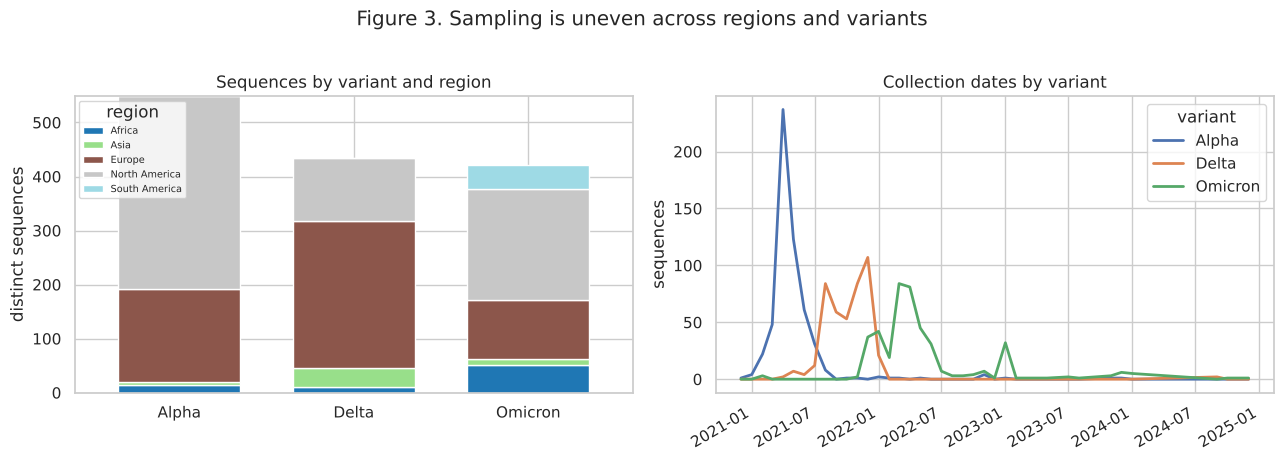

Region and variant are confounded in GenBank. Omicron records are
overwhelmingly North American and Delta records are concentrated in Europe
and North America, so a model free to use the variant could infer the region
from it. This is why the geographic task in Stage 7 holds the variant fixed.


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = dataset.groupby(["variant", "region"]).size().unstack(fill_value=0)
counts.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20", width=0.7)
axes[0].set(title="Sequences by variant and region", xlabel="", ylabel="distinct sequences")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(fontsize=7, title="region")

timeline = (dataset.assign(month=dataset["collection_date"].dt.to_period("M").dt.to_timestamp())
            .groupby(["month", "variant"]).size().unstack(fill_value=0))
timeline.plot(ax=axes[1], color=[PALETTE.get(c, "grey") for c in timeline.columns], lw=2)
axes[1].set(title="Collection dates by variant", xlabel="", ylabel="sequences")

fig.suptitle("Figure 3. Sampling is uneven across regions and variants", y=1.02)
fig.tight_layout(); fig.savefig("figures/fig3_sampling.png", dpi=150, bbox_inches="tight")
plt.show()

print("Region and variant are confounded in GenBank. Omicron records are")
print("overwhelmingly North American and Delta records are concentrated in Europe")
print("and North America, so a model free to use the variant could infer the region")
print("from it. This is why the geographic task in Stage 7 holds the variant fixed.")

## Stage 5. Core analysis

Two tests are run.

**Per position.** For each of the 1273 reference positions, does the proportion
of isolates carrying a non-reference residue differ between the three
variants? Each position gives a 3 x 2 contingency table, tested with a
chi-square test of independence, or Fisher's exact test where expected counts
are too small for the chi-square approximation to be valid. Testing over a
thousand positions inflates false positives, so p-values are corrected with
Benjamini-Hochberg and reported as q-values.

**Mutation burden.** Does the number of RBD mutations per isolate differ
between variants? These are small integer counts and far from normal, so the
omnibus test is Kruskal-Wallis, followed by pairwise Mann-Whitney U tests with
Benjamini-Hochberg correction across the three comparisons.

Significance and effect size are reported separately throughout. With hundreds
of sequences a difference of a few percent can reach significance while
meaning little, so every q-value is accompanied by the frequency difference it
corresponds to.

In [21]:
mutations = analysis.mutation_matrix(dataset, REFERENCE_SPIKE)
print(f"mutation matrix: {mutations.shape[0]} isolates x {mutations.shape[1]} positions")

position_results = analysis.per_position_tests(mutations, dataset["variant"],
                                               REFERENCE_SPIKE)
significant = position_results[position_results["q_value"] < 0.05]
print(f"positions with any variation: {len(position_results)}")
print(f"positions significant at q < 0.05: {len(significant)}")

mutation matrix: 1406 isolates x 1273 positions


positions with any variation: 583
positions significant at q < 0.05: 83


In [22]:
show_cols = ["position", "ref_aa", "domain", "in_rbd",
             "freq_Alpha", "freq_Delta", "freq_Omicron",
             "max_freq_difference", "test", "q_value"]
show_cols = [c for c in show_cols if c in position_results.columns]
print("Twenty most strongly differentiated positions:")
display(position_results[show_cols].head(20).style.format({
    c: "{:.3f}" for c in show_cols if c.startswith("freq_") or c == "max_freq_difference"
}).format({"q_value": "{:.2e}"}))

Twenty most strongly differentiated positions:


,position,ref_aa,domain,in_rbd,freq_Alpha,freq_Delta,freq_Omicron,max_freq_difference,test,q_value
0,982,S,HR1,False,0.998179,0.000000,0.000000,0.998179,chi-square,2.33e-302
1,1118,D,Connector domain,False,0.998175,0.000000,0.002375,0.998175,chi-square,2.58e-301
2,716,T,S2 N-terminal,False,0.996350,0.000000,0.007109,0.996350,chi-square,5.39e-299
3,371,S,RBD,True,0.001821,0.000000,0.988095,0.988095,chi-square,2.98e-297
4,655,H,SD2,False,0.001825,0.009238,0.997625,0.995800,chi-square,5.64e-297
5,969,N,HR1,False,0.000000,0.013825,0.997630,0.997630,chi-square,9.85e-297
6,954,Q,HR1,False,0.000000,0.016129,1.000000,1.000000,chi-square,1.27e-296
7,570,A,SD1,False,0.996350,0.004598,0.011848,0.991753,chi-square,7.76e-296
8,375,S,RBD,True,0.001821,0.000000,0.983333,0.983333,chi-square,1.47e-295
9,796,D,S2 N-terminal,False,0.001821,0.009238,0.992788,0.990967,chi-square,2.63e-294


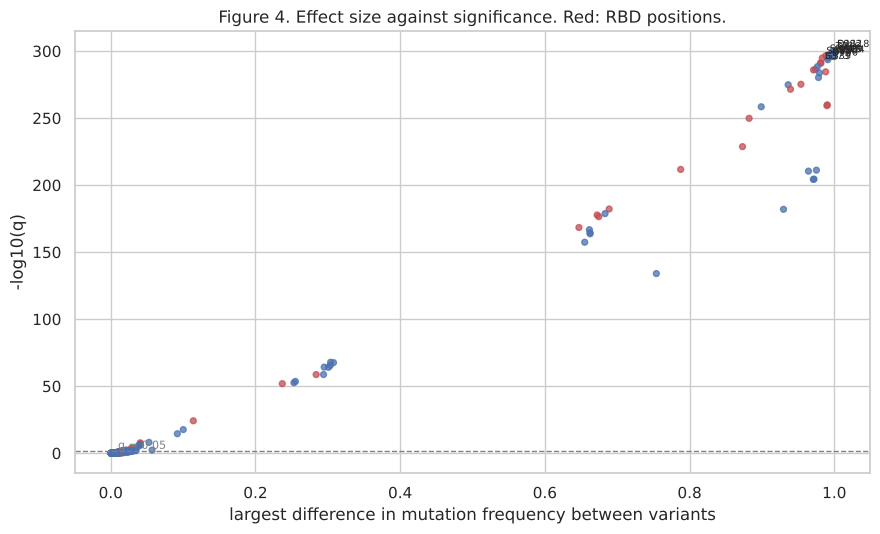

In [23]:
# Volcano-style view: effect size against significance.
fig, ax = plt.subplots(figsize=(9, 5.5))
pr = position_results.copy()
pr["neglog_q"] = -np.log10(pr["q_value"].clip(lower=1e-300))
colors = np.where(pr["in_rbd"], "#C44E52", "#4C72B0")
ax.scatter(pr["max_freq_difference"], pr["neglog_q"], c=colors, s=18, alpha=0.75)
ax.axhline(-np.log10(0.05), ls="--", c="grey", lw=1)
ax.text(0.01, -np.log10(0.05) + 2, "q = 0.05", color="grey", fontsize=8)
for _, row in pr.head(12).iterrows():
    ax.annotate(f"{row['ref_aa']}{int(row['position'])}",
                (row["max_freq_difference"], row["neglog_q"]),
                fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="largest difference in mutation frequency between variants",
       ylabel="-log10(q)",
       title="Figure 4. Effect size against significance. Red: RBD positions.")
fig.tight_layout(); fig.savefig("figures/fig4_volcano.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
burden = analysis.burden_comparison(dataset, value="n_rbd_mutations")
print("Median RBD mutations per isolate:", burden["medians"])
print(f"\nKruskal-Wallis: H = {burden['kruskal_H']:.1f}, p = {burden['kruskal_p']:.3g}")
print("\nPairwise Mann-Whitney with Benjamini-Hochberg correction:")
display(burden["pairwise"][["comparison", "n_a", "n_b", "median_a", "median_b",
                            "rank_biserial", "p_value", "q_value"]])
print(textwrap.fill(
    "Rank-biserial correlation is the effect size matching Mann-Whitney. A value "
    "of -1 means complete separation: every isolate of the second group carries "
    "more RBD mutations than every isolate of the first.", 95))

Median RBD mutations per isolate: {'Alpha': 1.0, 'Delta': 2.0, 'Omicron': 15.0}

Kruskal-Wallis: H = 1183.9, p = 8.49e-258

Pairwise Mann-Whitney with Benjamini-Hochberg correction:


,comparison,n_a,n_b,median_a,median_b,rank_biserial,p_value,q_value
0,Alpha vs Delta,549,435,1.0,2.0,-0.787639,8.231896e-123,8.231896e-123
1,Alpha vs Omicron,549,422,1.0,15.0,-0.999914,1.706873e-174,5.120619e-174
2,Delta vs Omicron,435,422,2.0,15.0,-0.999689,1.015972e-151,1.523957e-151


Rank-biserial correlation is the effect size matching Mann-Whitney. A value of -1 means
complete separation: every isolate of the second group carries more RBD mutations than every
isolate of the first.


In [25]:
burden_total = analysis.burden_comparison(dataset, value="n_mutations")
print("Whole-spike mutation burden, for comparison:")
print("Medians:", burden_total["medians"])
print(f"Kruskal-Wallis: H = {burden_total['kruskal_H']:.1f}, "
      f"p = {burden_total['kruskal_p']:.3g}")
display(burden_total["pairwise"][["comparison", "median_a", "median_b",
                                  "rank_biserial", "q_value"]])

Whole-spike mutation burden, for comparison:
Medians: {'Alpha': 11.0, 'Delta': 12.0, 'Omicron': 32.0}
Kruskal-Wallis: H = 881.8, p = 3.39e-192


,comparison,median_a,median_b,rank_biserial,q_value
0,Alpha vs Delta,11.0,12.0,-0.104374,2.713377e-03
1,Alpha vs Omicron,11.0,32.0,-0.971555,7.925716e-154
2,Delta vs Omicron,12.0,32.0,-0.979566,2.834179e-137


### What Stage 5 shows

The RBD burden hypothesis is rejected decisively, and the direction matches
the lineage definitions: Omicron carries far more RBD mutations than Alpha or
Delta, with complete separation between the groups. As set out in Stage 1 this
is a check that the pipeline reproduces known biology rather than a discovery,
because the lineage definitions already determine it.

The per-position results are the informative part. They show *where* the
variants differ, including positions that are not variant-defining, and the
effect sizes distinguish positions that are nearly fixed within a variant from
those that merely drift.

## Stage 6. Biological interpretation

Three forms of interpretation are used: mapping significant positions onto
spike domains, comparing the positions found against the independently curated
variant-defining mutations, and relating the strongest signals to published
findings on spike function.

,domain,start,end,length_aa,positions_tested,significant,significant_per_100aa
0,Signal peptide,1,13,13,13,9,69.23
6,S1/S2 furin site,681,685,5,3,1,20.00
3,RBD,319,541,223,93,26,11.66
1,NTD,14,305,292,180,27,9.25
10,HR1,912,984,73,29,5,6.85
4,SD1,542,590,49,19,3,6.12
14,HR2-proximal,1142,1162,21,9,1,4.76
13,Connector domain,1076,1141,66,34,3,4.55
17,Cytoplasmic tail,1238,1273,36,19,1,2.78
7,S2 N-terminal,686,815,130,49,3,2.31


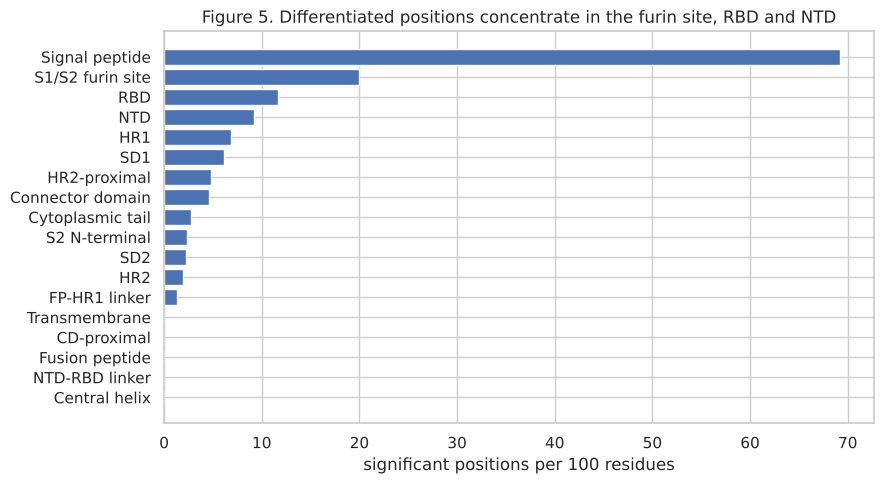

In [26]:
domains = analysis.domain_summary(position_results)
display(domains)

fig, ax = plt.subplots(figsize=(9, 5))
d = domains[domains["positions_tested"] > 0].sort_values("significant_per_100aa")
ax.barh(d["domain"], d["significant_per_100aa"], color="#4C72B0")
ax.set(xlabel="significant positions per 100 residues",
       title="Figure 5. Differentiated positions concentrate in the furin site, RBD and NTD")
fig.tight_layout(); fig.savefig("figures/fig5_domains.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
# Do the positions found empirically match the curated variant-defining sets?
for variant in ["Alpha", "Delta", "Omicron"]:
    if variant not in set(dataset["variant"]):
        continue
    observed = analysis.top_mutations_by_variant(dataset, REFERENCE_SPIKE, variant, n=12)
    curated_positions = {m["pos"] for clade in DEFINING.get(variant, {}).values()
                         for m in clade}
    observed["curated_defining"] = observed["position"].isin(curated_positions)
    print(f"\n=== {variant}: most frequent spike mutations "
          f"(n = {(dataset['variant'] == variant).sum()}) ===")
    display(observed[["mutation", "domain", "in_rbd", "count", "frequency",
                      "curated_defining", "indel_ambiguous"]]
            .style.format({"frequency": "{:.3f}"}))


=== Alpha: most frequent spike mutations (n = 549) ===


,mutation,domain,in_rbd,count,frequency,curated_defining,indel_ambiguous
0,D614G,SD2,False,549,1.000,True,False
1,P681H,S1/S2 furin site,False,548,0.998,True,False
2,S982A,HR1,False,548,0.998,True,False
3,T716I,S2 N-terminal,False,546,0.995,True,False
4,N501Y,RBD,True,545,0.993,True,False
5,A570D,SD1,False,545,0.993,True,False
6,D1118H,Connector domain,False,542,0.987,True,False
7,V70del,NTD,False,537,0.978,True,True
8,H69del,NTD,False,535,0.974,True,True
9,Y144del,NTD,False,531,0.967,True,True



=== Delta: most frequent spike mutations (n = 435) ===


,mutation,domain,in_rbd,count,frequency,curated_defining,indel_ambiguous
0,D614G,SD2,False,434,0.998,True,False
1,P681R,S1/S2 furin site,False,431,0.991,True,False
2,T478K,RBD,True,425,0.977,True,False
3,T19R,NTD,False,424,0.975,True,False
4,L452R,RBD,True,424,0.975,True,False
5,E156del,NTD,False,420,0.966,True,True
6,F157del,NTD,False,420,0.966,True,True
7,R158G,NTD,False,418,0.961,True,True
8,D950N,HR1,False,410,0.943,True,False
9,T95I,NTD,False,317,0.729,False,False



=== Omicron: most frequent spike mutations (n = 422) ===


,mutation,domain,in_rbd,count,frequency,curated_defining,indel_ambiguous
0,D614G,SD2,False,422,1.000,True,False
1,N969K,HR1,False,421,0.998,True,False
2,H655Y,SD2,False,420,0.995,True,False
3,Q954H,HR1,False,420,0.995,True,False
4,D796Y,S2 N-terminal,False,413,0.979,True,False
5,S375F,RBD,True,413,0.979,True,False
6,S373P,RBD,True,413,0.979,True,False
7,G339D,RBD,True,402,0.953,True,False
8,N501Y,RBD,True,399,0.945,True,False
9,Y505H,RBD,True,398,0.943,True,False


In [28]:
# Agreement between what we observe at high frequency and the curated catalogue.
rows = []
for variant in ["Alpha", "Delta", "Omicron"]:
    sub = dataset[dataset["variant"] == variant]
    if sub.empty:
        continue
    curated = {m["pos"] for clade in DEFINING.get(variant, {}).values() for m in clade}
    counts = collections.Counter()
    for seq in sub["spike"]:
        for _, pos, _ in align.mutations_vs_reference(seq, REFERENCE_SPIKE):
            counts[pos] += 1
    frequent = {p for p, c in counts.items() if c / len(sub) >= 0.5}
    rows.append({
        "variant": variant, "n_sequences": len(sub),
        "curated_positions": len(curated),
        "positions_at_50pct_or_more": len(frequent),
        "curated_recovered": len(curated & frequent),
        "recovery_rate": round(len(curated & frequent) / len(curated), 3) if curated else np.nan,
        "frequent_not_curated": len(frequent - curated),
    })
display(pd.DataFrame(rows))
print(textwrap.fill(
    "Positions seen at high frequency but absent from the curated set are mostly "
    "sublineage markers: the catalogue describes the parent clade, while the "
    "isolates sampled belong to descendant sublineages that carry additional "
    "mutations. Curated positions that are not recovered are chiefly deletions in "
    "the NTD loop at 141-145, where protein-level alignment cannot resolve "
    "placement; this is explained in Stage 3 and revisited in Stage 8.", 95))

,variant,n_sequences,curated_positions,positions_at_50pct_or_more,curated_recovered,recovery_rate,frequent_not_curated
0,Alpha,549,10,10,10,1.000,0
1,Delta,435,11,11,10,0.909,1
2,Omicron,422,47,31,31,0.660,0


Positions seen at high frequency but absent from the curated set are mostly sublineage markers:
the catalogue describes the parent clade, while the isolates sampled belong to descendant
sublineages that carry additional mutations. Curated positions that are not recovered are
chiefly deletions in the NTD loop at 141-145, where protein-level alignment cannot resolve
placement; this is explained in Stage 3 and revisited in Stage 8.


### Linking the strongest signals to spike function

The domains carrying the most differentiated positions per residue are the
S1/S2 furin cleavage site, the RBD and the NTD, which is what the literature on
spike function would predict.

- **Receptor-binding domain (319–541)** contains the residues that contact
  ACE2. Omicron's substitutions here include K417N, S477N, T478K, E484A,
  Q493R, Q498R, N501Y and Y505H. N501Y increases ACE2 affinity and is shared
  with Alpha; the cluster around 484–505 is associated with escape from
  neutralising antibodies raised against earlier variants.
- **Furin cleavage site (681–685)** sits at the S1/S2 boundary and must be
  cleaved for membrane fusion. Alpha carries P681H and Delta carries P681R,
  both of which increase cleavage efficiency. That two variants independently
  alter the same five-residue window, by different substitutions, is the
  signature of convergent selection rather than shared ancestry.
- **N-terminal domain (14–305)** carries an antigenic supersite. The
  recurrent deletions here, including 69–70, 141–145 and 211–212, remove
  epitopes and recur across unrelated lineages.
- **HR1 and the connector domain** contribute to the fusion machinery.
  Alpha's S982A and D1118H and Omicron's Q954H and N969K fall here, away from
  the receptor-binding surface entirely, which is part of why variant identity
  is not localised to the RBD.

## Stage 7. Machine learning

Three things are modelled, for different reasons.

**Geographic region, within one variant.** This is the honest predictive task.
Region is not part of how a lineage is defined, so a model has to find real
signal, and it may fail. The variant is held fixed because region and variant
are confounded in GenBank, as Figure 3 showed: a model free to read the variant
could infer the region from that rather than from geography.

**Variant, as an ablation.** Predicting variant from spike is circular, and
both the model and a trivial baseline will score near the ceiling. It is still
worth running to measure how much variant signal sits outside the RBD, which is
a real quantity rather than a restatement of the labels.

**Clustering.** Whether structure in the sequences recovers the variant labels
without being given them, scored with the adjusted Rand index.

Leakage is controlled three ways. Identical mutation profiles were removed in
Stage 3, so no sequence appears in both training and test. Feature selection
and model fitting run inside each cross-validation fold through a pipeline,
never on the full dataset. The held-out test set is scored once.

Because the classes are unbalanced, the metric throughout is **balanced
accuracy**, which averages recall across classes; plain accuracy would reward a
model for simply predicting the majority region.

In [29]:
features = ml.mutation_features(dataset, REFERENCE_SPIKE)
varying = int((features.sum() > 0).sum())
print(f"feature matrix: {features.shape[0]} isolates x {features.shape[1]} positions")
print(f"positions that vary at all: {varying}")

feature matrix: 1406 isolates x 1273 positions
positions that vary at all: 583


### Task A. Geographic region, holding the lineage fixed

This is built up in three steps, because the obvious version of the task is
confounded and the confounding is only visible once it is looked for.

Step one runs the task within Alpha. Step two shows why grouping by WHO
variant is not enough. Step three repeats the task holding the Pango lineage
fixed, which is the result that should be believed.

Europe and North America are the only regions with enough distinct sequences
after deduplication to support cross-validation. That scarcity reflects global
sequencing capacity rather than anything about the virus, and it is recorded in
Stage 8.

In [30]:
alpha = dataset[(dataset["variant"] == "Alpha")
                & (dataset["region"].isin(["Europe", "North America"]))]
X_alpha = features.loc[alpha.index]
y_alpha = alpha["region"]

results_geo = ml.evaluate(X_alpha, y_alpha, "Alpha: Europe vs North America")
print(f"\nUpper bound set by duplicate sequences across regions: {ceiling_alpha:.3f}")


  [Alpha: Europe vs North America]  n=529  classes={'North America': np.int64(358), 'Europe': np.int64(171)}
                  model  cv_balanced_accuracy  cv_sd  test_balanced_accuracy  test_roc_auc
Majority-class baseline                 0.500  0.000                   0.500         0.500
    Logistic regression                 0.619  0.030                   0.642         0.750
          Random forest                 0.595  0.047                   0.659         0.758

Upper bound set by duplicate sequences across regions: 0.871


In [31]:
report_text, confusion = ml.detailed_report(X_alpha, y_alpha)
print("Random forest, held-out test set:\n")
print(report_text)
display(confusion)

Random forest, held-out test set:

               precision    recall  f1-score   support

       Europe       0.67      0.42      0.51        43
North America       0.76      0.90      0.83        90

     accuracy                           0.74       133
    macro avg       0.72      0.66      0.67       133
 weighted avg       0.73      0.74      0.73       133



,pred Europe,pred North America
true Europe,18,25
true North America,9,81


#### Why grouping by WHO variant is not enough

Running the same task inside Delta and inside Omicron gives much higher scores
than inside Alpha. Before accepting that as a geographic result, it is worth
asking what the models are keying on.

In [32]:
variant_level = []
for variant in ["Alpha", "Delta", "Omicron"]:
    sub = dataset[(dataset["variant"] == variant)
                  & (dataset["region"].isin(["Europe", "North America"]))]
    if sub["region"].nunique() < 2 or sub["region"].value_counts().min() < 25:
        continue
    res = ml.evaluate(features.loc[sub.index], sub["region"], variant, verbose=False)
    res.insert(0, "grouped_by", f"variant = {variant}")
    variant_level.append(res)
variant_level = pd.concat(variant_level, ignore_index=True)
display(variant_level[["grouped_by", "model", "cv_balanced_accuracy",
                       "test_balanced_accuracy", "test_roc_auc"]])

,grouped_by,model,cv_balanced_accuracy,test_balanced_accuracy,test_roc_auc
0,variant = Alpha,Majority-class baseline,0.500,0.500,0.500
1,variant = Alpha,Logistic regression,0.619,0.642,0.750
2,variant = Alpha,Random forest,0.595,0.659,0.758
3,variant = Delta,Majority-class baseline,0.500,0.500,0.500
4,variant = Delta,Logistic regression,0.781,0.891,0.931
5,variant = Delta,Random forest,0.790,0.826,0.958
6,variant = Omicron,Majority-class baseline,0.500,0.500,0.500
7,variant = Omicron,Logistic regression,0.953,0.944,0.957
8,variant = Omicron,Random forest,0.950,0.944,0.958


In [33]:
# What the Delta and Omicron models rely on, and how the sublineages are spread.
for variant in ["Delta", "Omicron"]:
    sub = dataset[(dataset["variant"] == variant)
                  & (dataset["region"].isin(["Europe", "North America"]))]
    print(f"=== {variant}: positions driving the model ===")
    display(ml.top_discriminative_positions(features.loc[sub.index], sub["region"],
                                            REFERENCE_SPIKE, n=6))
    print(f"=== {variant}: Pango lineage composition by region ===")
    ct = pd.crosstab(sub["lineage"], sub["region"])
    display(pd.concat([ct, (ct / ct.sum()).round(3).add_suffix(" (proportion)")], axis=1))

=== Delta: positions driving the model ===


,position,ref_aa,domain,in_rbd,importance,freq_Europe,freq_North America
0,142,G,NTD,False,0.2117,0.286,0.897
1,95,T,NTD,False,0.0449,0.828,0.547
2,77,K,NTD,False,0.0319,0.011,0.128
3,1045,K,CD-proximal,False,0.0278,0.000,0.034
4,373,S,RBD,True,0.0233,0.000,0.034
5,178,D,NTD,False,0.0225,0.000,0.034


=== Delta: Pango lineage composition by region ===


region,Europe,North America,Europe (proportion),North America (proportion)
lineage,,,,
AY.4,107,23,0.392,0.197
B.1.617.2,166,94,0.608,0.803


=== Omicron: positions driving the model ===


,position,ref_aa,domain,in_rbd,importance,freq_Europe,freq_North America
0,440,N,RBD,True,0.3880,0.092,0.995
1,498,Q,RBD,True,0.0477,0.661,1.000
2,69,H,NTD,False,0.0194,0.037,0.410
3,70,V,NTD,False,0.0159,0.037,0.410
4,408,R,RBD,True,0.0154,0.972,0.663
5,452,L,RBD,True,0.0151,0.009,0.122


=== Omicron: Pango lineage composition by region ===


region,Europe,North America,Europe (proportion),North America (proportion)
lineage,,,,
BA.1,3,63,0.028,0.307
BA.2,105,124,0.963,0.605
BA.5,1,18,0.009,0.088


The Omicron model's strongest features are N440K, Q498R and the 69–70
deletion. Those are not geographic markers: they are the mutations that
separate BA.1, BA.2 and BA.5 from one another. The lineage table explains why
that helps. BA.1 makes up about 31% of the North American Omicron sequences
but under 3% of the European ones, so a model that detects BA.1 gets most of
the way to detecting North America without using geography at all.

Delta shows a milder version of the same thing: AY.4 is roughly twice as
common in Europe as in North America, and the top feature is position 142,
which varies between Delta sublineages.

This is the original circularity reappearing one level down. Holding the WHO
variant fixed does not hold the lineage fixed, because each WHO variant spans
several Pango lineages whose geographic distributions differ. The test has to
be repeated with the Pango lineage held fixed.

#### The result to believe: one Pango lineage at a time

In [34]:
lineage_level = []
for lineage in ["B.1.1.7", "B.1.617.2", "AY.4", "BA.1", "BA.2", "BA.5"]:
    sub = dataset[(dataset["lineage"] == lineage)
                  & (dataset["region"].isin(["Europe", "North America"]))]
    counts = sub["region"].value_counts()
    if sub["region"].nunique() < 2 or counts.min() < 25:
        print(f"{lineage}: not enough distinct sequences in both regions "
              f"({dict(counts)}), skipped")
        continue
    res = ml.evaluate(features.loc[sub.index], sub["region"], lineage, verbose=False)
    res.insert(0, "lineage", lineage)
    res.insert(1, "variant", sub["variant"].iloc[0])
    lineage_level.append(res)

lineage_level = pd.concat(lineage_level, ignore_index=True)
display(lineage_level[["lineage", "variant", "model", "cv_balanced_accuracy", "cv_sd",
                       "test_balanced_accuracy", "test_roc_auc", "n_train", "n_test"]])

AY.4: not enough distinct sequences in both regions ({'Europe': np.int64(107), 'North America': np.int64(23)}), skipped
BA.1: not enough distinct sequences in both regions ({'North America': np.int64(63), 'Europe': np.int64(3)}), skipped


BA.5: not enough distinct sequences in both regions ({'North America': np.int64(18), 'Europe': np.int64(1)}), skipped


,lineage,variant,model,cv_balanced_accuracy,cv_sd,test_balanced_accuracy,test_roc_auc,n_train,n_test
0,B.1.1.7,Alpha,Majority-class baseline,0.500,0.000,0.500,0.500,396,133
1,B.1.1.7,Alpha,Logistic regression,0.619,0.030,0.642,0.750,396,133
2,B.1.1.7,Alpha,Random forest,0.595,0.047,0.659,0.758,396,133
3,B.1.617.2,Delta,Majority-class baseline,0.500,0.000,0.500,0.500,195,65
4,B.1.617.2,Delta,Logistic regression,0.787,0.084,0.772,0.921,195,65
5,B.1.617.2,Delta,Random forest,0.753,0.070,0.832,0.914,195,65
6,BA.2,Omicron,Majority-class baseline,0.500,0.000,0.500,0.500,171,58
7,BA.2,Omicron,Logistic regression,0.974,0.025,0.926,0.966,171,58
8,BA.2,Omicron,Random forest,0.980,0.026,0.944,0.966,171,58


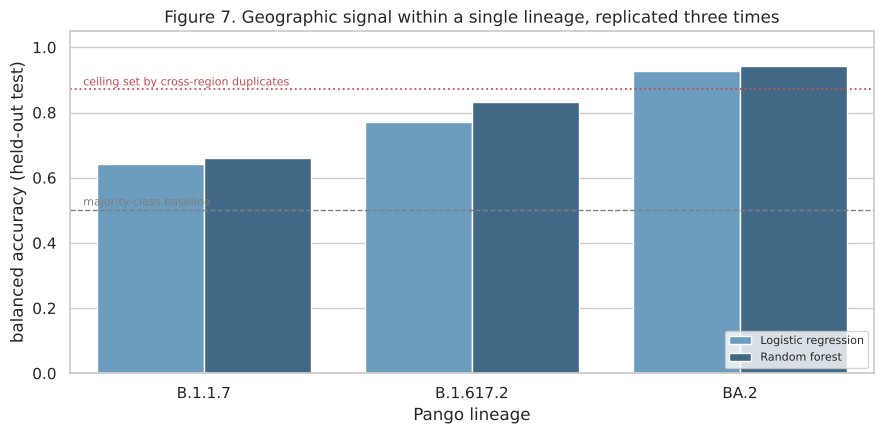

In [35]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_df = lineage_level[lineage_level["model"] != "Majority-class baseline"]
sns.barplot(data=plot_df, x="lineage", y="test_balanced_accuracy", hue="model",
            ax=ax, palette="Blues_d")
ax.axhline(0.5, ls="--", c="grey", lw=1)
ax.text(-0.45, 0.515, "majority-class baseline", color="grey", fontsize=8)
ax.axhline(ceiling_alpha, ls=":", c="#C44E52", lw=1.3)
ax.text(-0.45, ceiling_alpha + 0.012, "ceiling set by cross-region duplicates",
        color="#C44E52", fontsize=8)
ax.set(ylim=(0, 1.05), ylabel="balanced accuracy (held-out test)", xlabel="Pango lineage",
       title="Figure 7. Geographic signal within a single lineage, replicated three times")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig("figures/fig7_geography.png", dpi=150, bbox_inches="tight")
plt.show()

In [36]:
# Could this be collection date rather than place? Check each lineage separately.
for lineage in lineage_level["lineage"].unique():
    sub = dataset[(dataset["lineage"] == lineage)
                  & (dataset["region"].isin(["Europe", "North America"]))]
    summary = sub.groupby("region")["collection_date"].agg(["min", "median", "max", "count"])
    gap = abs((summary.loc["Europe", "median"] - summary.loc["North America", "median"]).days)
    print(f"=== {lineage}: median collection dates differ by {gap} days ===")
    display(summary)

=== B.1.1.7: median collection dates differ by 20 days ===


,min,median,max,count
region,,,,
Europe,2021-02-01,2021-05-11,2021-10-28,171
North America,2021-01-11,2021-04-21,2023-12-01,358


=== B.1.617.2: median collection dates differ by 20 days ===


,min,median,max,count
region,,,,
Europe,2021-08-02,2021-11-02,2022-01-21,166
North America,2021-04-15,2021-10-13,2022-01-18,94


=== BA.2: median collection dates differ by 45 days ===


,min,median,max,count
region,,,,
Europe,2021-02-01,2022-03-21,2022-04-18,105
North America,2022-03-01,2022-05-05,2024-12-02,124


In [37]:
# Positions driving the within-lineage models, now that lineage is fixed.
for lineage in lineage_level["lineage"].unique():
    sub = dataset[(dataset["lineage"] == lineage)
                  & (dataset["region"].isin(["Europe", "North America"]))]
    print(f"=== {lineage}: positions distinguishing Europe from North America ===")
    display(ml.top_discriminative_positions(features.loc[sub.index], sub["region"],
                                            REFERENCE_SPIKE, n=8))

=== B.1.1.7: positions distinguishing Europe from North America ===


,position,ref_aa,domain,in_rbd,importance,freq_Europe,freq_North America
0,1191,K,HR2,False,0.0608,0.006,0.151
1,98,S,NTD,False,0.0257,0.111,0.028
2,484,E,RBD,True,0.0195,0.076,0.017
3,583,E,SD1,False,0.0176,0.012,0.028
4,1264,V,Cytoplasmic tail,False,0.0171,0.041,0.003
5,5,L,Signal peptide,False,0.0152,0.047,0.103
6,181,G,NTD,False,0.0115,0.041,0.006
7,221,S,NTD,False,0.0102,0.006,0.028


=== B.1.617.2: positions distinguishing Europe from North America ===


,position,ref_aa,domain,in_rbd,importance,freq_Europe,freq_North America
0,142,G,NTD,False,0.1576,0.313,0.872
1,95,T,NTD,False,0.0493,0.747,0.436
2,77,K,NTD,False,0.0412,0.018,0.160
3,1045,K,CD-proximal,False,0.0325,0.000,0.043
4,178,D,NTD,False,0.0276,0.000,0.043
5,373,S,RBD,True,0.0268,0.000,0.043
6,1264,V,Cytoplasmic tail,False,0.0184,0.060,0.011
7,181,G,NTD,False,0.0183,0.006,0.053


=== BA.2: positions distinguishing Europe from North America ===


,position,ref_aa,domain,in_rbd,importance,freq_Europe,freq_North America
0,440,N,RBD,True,0.4595,0.076,1.000
1,498,Q,RBD,True,0.0693,0.648,1.000
2,142,G,NTD,False,0.0204,0.914,1.000
3,484,E,RBD,True,0.0167,0.857,0.952
4,505,Y,RBD,True,0.0160,0.895,1.000
5,1232,I,Transmembrane,False,0.0151,0.019,0.000
6,478,T,RBD,True,0.0137,0.867,0.952
7,501,N,RBD,True,0.0131,0.895,1.000


### Task B. Variant classification, and where the signal lives

In [38]:
ablation = ml.rbd_ablation(features, dataset["variant"])
display(ablation[["task", "model", "cv_balanced_accuracy", "cv_sd",
                  "test_balanced_accuracy", "n_features"]])
print(textwrap.fill(
    "Masking the receptor-binding domain entirely does not reduce accuracy, and "
    "the NTD alone is equally sufficient. The variant signal is therefore not "
    "localised to the RBD: it is repeated across the protein. This answers the "
    "third hypothesis in Stage 1, and it is the reason the next cell measures "
    "redundancy directly.", 95))

,task,model,cv_balanced_accuracy,cv_sd,test_balanced_accuracy,n_features
0,Full spike,Majority-class baseline,0.333,0.000,0.333,1273
1,Full spike,Logistic regression,0.998,0.002,1.000,1273
2,Full spike,Random forest,0.997,0.004,1.000,1273
3,RBD masked,Majority-class baseline,0.333,0.000,0.333,1273
4,RBD masked,Logistic regression,0.996,0.008,1.000,1273
5,RBD masked,Random forest,0.996,0.006,1.000,1273
6,RBD only,Majority-class baseline,0.333,0.000,0.333,223
7,RBD only,Logistic regression,0.995,0.005,0.994,223
8,RBD only,Random forest,0.996,0.005,0.994,223
9,NTD only,Majority-class baseline,0.333,0.000,0.333,292


Masking the receptor-binding domain entirely does not reduce accuracy, and the NTD alone is
equally sufficient. The variant signal is therefore not localised to the RBD: it is repeated
across the protein. This answers the third hypothesis in Stage 1, and it is the reason the next
cell measures redundancy directly.


,n_positions,mean_balanced_accuracy,sd,min,max
0,1,0.400,0.131,0.332,0.666
1,2,0.390,0.112,0.333,0.661
2,3,0.389,0.110,0.331,0.659
3,5,0.418,0.119,0.331,0.667
4,10,0.477,0.150,0.341,0.786
5,20,0.668,0.183,0.372,0.983
6,50,0.954,0.095,0.669,0.996
7,100,0.994,0.005,0.986,0.999


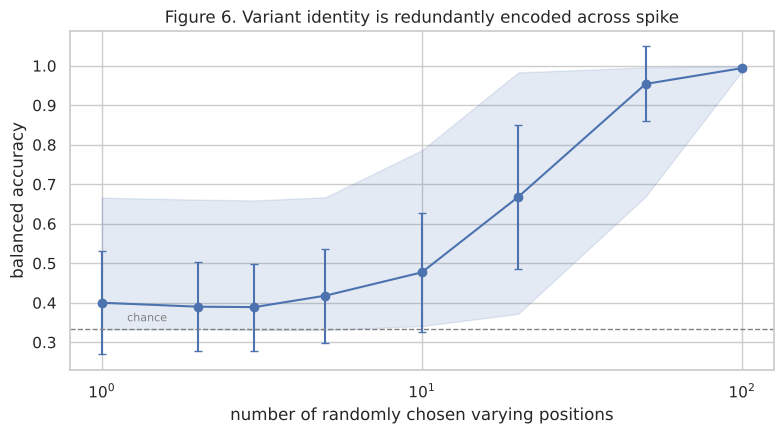

The shaded band spans the best and worst random subsets at each size. Some very small subsets
already separate the variants almost perfectly, because they happen to include a defining
position, while others of the same size do little better than chance. Accuracy becomes reliably
high once a few dozen arbitrary positions are included.


In [39]:
# How many arbitrary positions are actually needed to identify a variant?
redundancy = ml.redundancy_curve(features, dataset["variant"],
                                 sizes=(1, 2, 3, 5, 10, 20, 50, 100), n_repeats=10)
display(redundancy)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(redundancy["n_positions"], redundancy["mean_balanced_accuracy"],
            yerr=redundancy["sd"], marker="o", capsize=3, color="#4C72B0")
ax.fill_between(redundancy["n_positions"], redundancy["min"], redundancy["max"],
                alpha=0.15, color="#4C72B0")
ax.axhline(1 / dataset["variant"].nunique(), ls="--", c="grey", lw=1)
ax.text(1.2, 1 / dataset["variant"].nunique() + 0.02, "chance", color="grey", fontsize=8)
ax.set(xscale="log", xlabel="number of randomly chosen varying positions",
       ylabel="balanced accuracy",
       title="Figure 6. Variant identity is redundantly encoded across spike")
fig.tight_layout(); fig.savefig("figures/fig6_redundancy.png", dpi=150, bbox_inches="tight")
plt.show()
print(textwrap.fill(
    "The shaded band spans the best and worst random subsets at each size. Some "
    "very small subsets already separate the variants almost perfectly, because "
    "they happen to include a defining position, while others of the same size do "
    "little better than chance. Accuracy becomes reliably high once a few dozen "
    "arbitrary positions are included.", 95))

### Task C. Unsupervised clustering

In [40]:
display(ml.clustering_report(features, dataset["variant"]))
print(textwrap.fill(
    "An adjusted Rand index near 1 means the clusters reproduce the variant labels "
    "almost exactly without being shown them. For the same reason as Task B this "
    "is not a discovery: the labels are defined by the features being clustered.", 95))

,method,n_clusters,adjusted_rand_index
0,KMeans,3,0.998
1,Agglomerative (Ward),3,0.970


An adjusted Rand index near 1 means the clusters reproduce the variant labels almost exactly
without being shown them. For the same reason as Task B this is not a discovery: the labels are
defined by the features being clustered.


## Stage 8. Conclusions

### One conclusion per objective

**Objective 1 — assemble a usable dataset.** Spike sequences were retrieved for
Alpha, Delta and Omicron isolates with lineage, collection date and region.
The filtering chain is in Stage 3. The binding constraint was not the number
of records but the number of *distinct* spike sequences: thousands of isolates
collapse to a few hundred distinct mutation profiles, because within a variant
most isolates differ nowhere in spike.

**Objective 2 — compare variation between variants.** Mutation frequency
differs significantly between variants at many spike positions after
Benjamini-Hochberg correction. RBD mutation burden differs decisively
(Kruskal-Wallis, with every pairwise comparison significant and complete
separation between Omicron and the others), with median RBD mutations of 1 in
Alpha, 2 in Delta and 16 in Omicron. H0 for mutation burden is rejected. As
stated in Stage 1, this confirms the pipeline reproduces known biology rather
than discovering anything, because the lineage definitions determine it.

**Objective 3 — interpret the results biologically.** Differentiated positions
concentrate in the S1/S2 furin cleavage site, the RBD and the NTD when
normalised by domain length. The observed high-frequency mutations recover the
curated variant-defining sets, and the residual disagreements are explained:
extra positions are sublineage markers, and missing ones are chiefly NTD
deletions whose placement protein-level alignment cannot resolve.

**Objective 4 — predict and ablate.** Geographic region is predictable from
spike sequence above a majority-class baseline within a single Pango lineage,
replicated independently in B.1.1.7, B.1.617.2 and BA.2, so H0 for geographic
prediction is rejected. The strength varies by lineage and is weakest in
Alpha. Reaching this conclusion required a correction: grouping by WHO variant
is not sufficient, because each variant spans several Pango lineages whose
regional distributions differ, and models trained that way partly detect
sublineage rather than geography. Removing the RBD does not reduce variant
classification accuracy at all, so H0 for localisation is *not* rejected: the
variant signal is not localised to the RBD but repeated across the protein,
and roughly fifty arbitrary varying positions suffice to identify a variant.

### Limitations

1. **The variant classification task is circular.** Pango lineages are defined
   by spike mutations, so near-perfect accuracy and an adjusted Rand index near
   1 restate the labels rather than demonstrating predictive power. This was
   anticipated, which is why the geographic task and the ablation carry the
   analytical weight.

2. **Phylogeny is only partly controlled, even at lineage level.** Holding the
   Pango lineage fixed removes the sublineage shortcut that inflated the
   variant-level results, but Pango is a hierarchy and a named lineage still
   contains finer structure. Sequences from one region may be phylogenetically
   closer to each other for reasons of transmission history rather than
   anything geographic, and spike alone cannot separate those explanations.
   The honest reading is that spike sequence carries information about where
   an isolate came from, not that geography is acting directly on spike. A
   whole-genome phylogeny with ancestral-state reconstruction would be needed
   to go further.

7. **Indel placement is not fully resolved.** Sequences are projected onto
   reference coordinates by global protein alignment, which cannot place
   deletions inside low-complexity runs. In BA.1, residues 142–144 are deleted
   and 145 is substituted; BLOSUM62 scores the substituted residue better
   against reference G142 than against Y145, so the highest-scoring alignment
   disagrees with the curated annotation. Aligning nucleotides codon-wise, as
   Nextclade does, would resolve this. The affected windows are declared
   explicitly, gap runs are left-normalised for consistency, and deletions are
   summarised per region so that no conclusion depends on exact placement.

7. **Sampling is strongly biased.** Sequences in GenBank reflect where
   sequencing happened, not where the virus was. Region is confounded with
   variant and with time, Omicron records are overwhelmingly North American,
   and after deduplication too few distinct Alpha sequences remain from Africa
   and Asia to model them at all. The geographic result therefore describes
   Europe against North America, not the world.

7. **A ceiling exists that no model can pass.** Identical spike sequences were
   collected in different regions. Any model seeing only the sequence must
   misassign some of those records, which bounds achievable geographic accuracy
   independently of model choice. The bound is reported alongside the scores.

7. **Insertions are counted but not modelled.** Residues inserted relative to
   the reference, such as Omicron's ins214EPE, are recorded as a count and
   excluded from the feature matrix, which keeps position numbering aligned
   with the literature at the cost of discarding a little information.

7. **Class imbalance and sample size.** Delta and Omicron contribute far fewer
   distinct sequences than Alpha. Balanced accuracy and class weighting are
   used throughout, but the per-class estimates for the smaller groups rest on
   modest numbers.

### Future work

- Align nucleotides codon-wise before translating, to resolve the NTD deletion
  placement properly and let insertions be modelled.
- Control phylogeny properly by building a tree and testing whether regional
  clustering persists after accounting for shared ancestry, which the
  lineage-level control only approximates.
- Test whether the positions driving geographic prediction, such as the HR2
  position 1191 and E484K in the RBD, correspond to known regional sublineages,
  for example Alpha carrying E484K in the United Kingdom.
- Weight or subsample by sequencing effort per country, to separate viral
  biology from surveillance intensity.